# Notebook Kaggle : Diabetes_large_diabeteset.csv  
https://www.kaggle.com/datasets/datascikhan/diabetes  

### Données :
**100.000** lignes patient  
**209** features



### Cibles possibles :
**Catégorielles :**
- `diabetes_status` (0 = No, 1 = Yes)  
  
|Class|Approximate %|
|---:|:---:|
|No Diabetes : $0$| 72,03 %|
|Diabetes : $1$|27,97 %|   

- `diabetes_type` (No diabetes, Type 1, Type 2, Gestational, Other)   
  
|Diabetes_type|Nombre|Pourcentage|
|---|:---:|:---:|
|No Diabetes|71.974|72,37 %|
|Type 2|25.194|25,33 %|
|Type 1|3|0,00 %|
|Other Diabetes|2.174|2,19 %|
|Gestational Diabetes|108|0,11 %|



## 1. Pré-visualisation des données et pré-nettoyage

In [1]:
import time
import warnings
from collections import Counter
from concurrent.futures import ThreadPoolExecutor
from functools import partial
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from annexes import ArrondirModalites, ColumnFilter
from IPython.display import display
from joblib import Memory, Parallel, delayed
from scipy.stats import binom, ks_2samp
from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.dummy import DummyClassifier
from sklearn.experimental import enable_iterative_imputer
from sklearn.feature_selection import RFECV, SelectKBest, f_classif, mutual_info_classif
from sklearn.impute import IterativeImputer
from sklearn.inspection import permutation_importance
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    ConfusionMatrixDisplay,
    RocCurveDisplay,
    average_precision_score,
    confusion_matrix,
    f1_score,
    precision_recall_curve,
    roc_auc_score,
)
from sklearn.model_selection import StratifiedKFold, cross_validate, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder,
    OrdinalEncoder,
    StandardScaler,
)
from sklearn.svm import LinearSVC
from xgboost import DMatrix, XGBClassifier


In [2]:
diabete = pd.read_csv("diabetes_large_dataset.csv")
diabete = diabete.replace(["NA", "N/A", "unknown", ""], np.nan)
d_complet = diabete.copy()
diabete.head()

,patient_id,record_id,age,age_group,sex,gender,ethnicity,race_group,marital_status,education_level,...,diabetes_risk_score,overall_health_score,physical_health_score,mental_wellbeing_score,quality_of_life_score,chronic_condition_count,hospitalization_history,emergency_visit_history,diabetes_status,diabetes_type
0,P000001,R00000001,57.0,51-60,Male,Male,Black,Black,Married,Some College,...,2.4,86.8,86.0,64.7,89.4,1,2,0,NaN,No Diabetes
1,P000002,R00000002,47.0,41-50,Female,Female,White,White,Married,High School,...,2.7,85.5,86.2,78.4,80.0,3,0,0,NaN,No Diabetes
2,P000003,R00000003,59.0,51-60,Male,Male,Black,Black,Married,Some College,...,19.3,66.0,66.1,56.7,64.7,2,0,1,1.0,Type 2
3,P000004,R00000004,72.0,71-90,Female,Female,Black,Black,Single,Master,...,0.9,61.8,64.4,68.6,59.6,3,0,0,0.0,No Diabetes
4,P000005,R00000005,46.0,41-50,Male,Male,Hispanic,Hispanic,Married,Bachelor,...,6.3,80.4,81.8,73.0,76.7,1,0,2,0.0,No Diabetes


### **1.1 Suppression de colonnes**
Ici on se base sur un dataset synthétiques de données hospitalières, contenant de nombreuses informations.  
Notre objectif étant de prédire le diabete chez un patient, on souhaite en particulier écarter :
- les données liées directement à un diagnostique de diabetes pour éviter le *diabete leakage*.  
- les données "expertes" de scores qui demande les connaissances d'un spécialiste (car on essayera de trouver une méthode donnant une prédiction basées uniquement sur des test (prise de sang ...) réalisable à large échelle).  
- les données en doubles.

In [3]:
display(pd.crosstab(diabete["sex"], diabete["gender"], margins=True, normalize="all").round(3))

# Fuite de données vérifiée par la courbe de suppression gloutonne (XGBoost, split 80/20) :
# AUC reste à 1.000 jusqu'à ce qu'ils soient tous suppirmés (porteurs redondants de la target), puis chute à 0.83.
colonnes_fuite = [
    "diabetes_type", "diabetes_risk_score",
    "overall_health_score", "physical_health_score",
    "fasting_glucose_mg_dl", "previous_diabetes_diagnosis",
    "chronic_condition_count",
]

diabete.drop(
    columns=[
        # Identifiants
        "patient_id", "record_id",

        # Fuite de données vérifiée (AUC 1.00 -> 0.83)
        *colonnes_fuite,

        # Critère de diagnostic :
            # Retrait car on veut se mettre dans un état d'esprit de dépistage, pas de diagnostic 
        "hba1c_percent", "two_hour_glucose_mg_dl", "random_glucose_mg_dl",
        "post_meal_glucose_mg_dl", "glucose_variability",

        # Score pré-calculés composites :
            # On perd donc des perfs sur les modèles car on enlève de l'information experte, mais on essaye de rester en dépistage
        *diabete.columns[diabete.columns.str.endswith("score")].tolist(),

        # Valeure connues uniquement après un diagnostic de diabète :
            # Retrait pour rester en dépistage, pas de diagnostic

        "diabetes_medication", "metformin_use", "insulin_use",
        "sulfonylurea_use", "sglt2_inhibitor_use", "glp1_medication_use",
        "dpp4_inhibitor_use", "glucose_monitoring_frequency",
        "home_glucose_monitoring", "continuous_glucose_monitor",
        "diabetes_education_received", "nutritionist_visits_per_year",
        "medication_adherence_percent", "self_management_score",
        "diabetic_retinopathy", "diabetic_neuropathy",
        "diabetic_nephropathy", "diabetic_foot_problem",
        "hypoglycemia_history", "hyperglycemia_history",
        "diabetic_ketoacidosis_history", "diabetes_complication_count",

        # Colonnes dupliquées
        "gender", "hypertension_status", "kidney_disease_status",
        "healthcare_access", "urban_rural", "urbanization_level",
        "race_group", "resting_heart_rate", "alcohol_use", "smoking_frequency",

        # Catégories construites à partir d'autres colonnes que l'on garde déjà
        "age_group", "bmi_category", "income_level",
        "obesity_diagnosis", "proteinuria_status",

        # Valeurs calculées à partir d'autres colonnes que l'on garde déjà
        "estimated_average_glucose_mg_dl", "pulse_pressure",
        "mean_arterial_pressure", "waist_to_hip_ratio", "vldl_mg_dl",
        "cholesterol_hdl_ratio", "non_hdl_cholesterol", "lean_body_mass_kg",
        "body_surface_area", "resting_metabolic_rate",
        "insulin_resistance_index", "hematocrit_percent", "mch_pg",
        "mchc_g_dl", "fat_percent", "urine_albumin_creatinine_ratio",

    ],
    inplace=True,
    errors="ignore",  # skip columns that are already gone
)


print(diabete.shape)

# Remove duplicate rows and rows without a target
diabete = diabete.drop_duplicates()
diabete = diabete.dropna(subset=['diabetes_status'])
print("Final shape:", diabete.shape)

gender,Female,Male,Non-Bi,All
sex,,,,
Female,0.507,0.000,0.005,0.512
Male,0.000,0.483,0.005,0.488
All,0.507,0.483,0.010,1.000


(100000, 130)
Final shape: (97980, 130)


### 1.3 Présentation rapide des données


**Général**

In [5]:
num_cols = diabete.select_dtypes("number").columns.drop("diabetes_status").tolist()
cat_cols = diabete.select_dtypes(exclude="number").columns.tolist()
print(f"Colonnes numériques : {len(num_cols)} | Colonnes catégorielles : {len(cat_cols)}")
diabete.head()

Colonnes numériques : 73 | Colonnes catégorielles : 56


,age,sex,ethnicity,marital_status,education_level,employment_status,occupation_category,annual_income,household_size,dependents,...,public_transport_access,community_health_resources,country,region,state_province,city_category,climate_zone,hospitalization_history,emergency_visit_history,diabetes_status
2,59.0,Male,Black,Married,Some College,Employed,Professional,31057.78,4,3,...,Excellent,22.6,USA,Midwest,State B,Suburban,Temperate,0,1,1.0
3,72.0,Female,Black,Single,Master,Retired,Technical,33333.87,4,2,...,Good,30.2,Canada,Midwest,State C,Metropolitan,Arid,0,0,0.0
4,46.0,Male,Hispanic,Married,Bachelor,Employed,Professional,36989.40,1,0,...,Fair,61.7,USA,Northeast,State A,Small Town,Temperate,0,2,0.0
5,46.0,Female,White,Divorced,Some College,Employed,Professional,106236.11,4,2,...,Good,47.0,USA,Southwest,Province B,Suburban,Arid,0,0,0.0
6,73.0,Female,Black,Widowed,Bachelor,Retired,Professional,55958.85,3,1,...,Good,71.1,USA,Southwest,Province B,Urban,Temperate,0,0,1.0


**Valeurs Manquantes NAs**  
On a 35 colonnes avec entre 1 et 10% de NaN (83.612 lignes impactées)  
/!\ 1 colonne `age_at_menopause` pose problème : Les hommes ne sont pas concernés et les toutes les femmes n'ont pas encore atteind l'âge : NaN si et seulement si pas encore ménoposé = 82% des patients. 2 choix :
- `age_at_menopause` inutile pour diagnostiquer le diabète = on enlève la colonne.
- `age_at_menopause` très utile = on traite les NAs


In [6]:
def calculer_stats_na(df, describe=False):
    tableau_na = pd.DataFrame({
        "nombre_NA": df.isna().sum(),
        "pourcentage_NA": df.isna().mean().mul(100).round(2)
    })

    tableau_na = tableau_na[tableau_na["nombre_NA"] > 0]
    tableau_na = tableau_na.sort_values(
        by="pourcentage_NA",
        ascending=False
    )

    nombre_total_na = int(tableau_na["nombre_NA"].sum())
    nombre_lignes_avec_na = int(df.isna().any(axis=1).sum())

    if describe:
        display(tableau_na)
        print(f"Nombre total de NaN : {nombre_total_na:,}")
        print(f"Nombre de lignes ayant au moins un NaN : {nombre_lignes_avec_na:,}")
    else:
        return tableau_na, nombre_total_na, nombre_lignes_avec_na


calculer_stats_na(diabete, describe=True)
diabete_sans_menaupose = diabete.drop(columns=["age_at_menopause"], errors="ignore")
_, _, nombre_lignes_avec_na = calculer_stats_na(diabete_sans_menaupose)
print(f"Nombre de lignes ayant au moins un NaN (sans menopause): {nombre_lignes_avec_na:,}")

,nombre_NA,pourcentage_NA
age_at_menopause,80616,82.28
fasting_insulin_uIU_ml,9973,10.18
urine_albumin_mg_g,9928,10.13
folate_ng_ml,9851,10.05
vitamin_d_ng_ml,9815,10.02
public_transport_access,9800,10.00
ferritin_ng_ml,9800,10.00
c_peptide_ng_ml,9759,9.96
vitamin_b12_pg_ml,9706,9.91
waist_circumference_cm,5009,5.11


Nombre total de NaN : 262,217
Nombre de lignes ayant au moins un NaN : 95,482
Nombre de lignes ayant au moins un NaN (sans menopause): 83,612


**statistiques descriptives**

In [7]:
num = diabete[num_cols]

# --- Statistiques descriptives (colonnes numériques) + asymétrie
stats_desc = num.describe().T
stats_desc["asymetrie"] = num.skew().round(2)
display(stats_desc.round(2))
display(num["cigarettes_per_day"].describe().round(2))

# --- Valeurs aberrantes : méthode de l'écart interquartile (IQR)
q1, q3 = num.quantile(0.25), num.quantile(0.75)
iqr = q3 - q1
borne_basse, borne_haute = q1 - 1.5 * iqr, q3 + 1.5 * iqr
aberrantes = (num.lt(borne_basse) | num.gt(borne_haute))

stats_aberrantes = pd.DataFrame({"nombre_aberrantes": aberrantes.sum(),
                                 "pourcentage_aberrantes": aberrantes.mean().mul(100).round(2)})
stats_aberrantes = stats_aberrantes[stats_aberrantes["nombre_aberrantes"] > 0]
stats_aberrantes = stats_aberrantes.sort_values(by="pourcentage_aberrantes", ascending=False)
display(stats_aberrantes.head(10))
print(f"Colonnes avec au moins une valeur aberrante : {len(stats_aberrantes)} sur {len(num_cols)} ({len(stats_aberrantes)/len(num_cols)*100:.2f}%)")



,count,mean,std,min,25%,50%,75%,max,asymetrie
age,96027.0,49.61,14.73,18.0,39.00,50.00,60.00,90.00,0.08
annual_income,97980.0,61658.53,42485.07,10000.0,30199.87,51408.81,79986.93,282671.22,1.39
household_size,97980.0,3.22,1.68,1.0,2.00,3.00,4.00,8.00,0.73
dependents,97980.0,1.78,1.62,0.0,0.00,2.00,3.00,6.00,0.78
height_cm,93122.0,168.33,9.40,140.0,161.40,168.00,175.20,203.00,0.10
...,...,...,...,...,...,...,...,...,...
number_of_pregnancies,97980.0,0.77,1.15,0.0,0.00,0.00,1.00,9.00,1.58
age_at_menopause,17364.0,50.96,3.97,40.0,48.00,51.00,54.00,60.00,-0.06
distance_to_healthcare_km,97980.0,5.49,5.00,0.5,1.90,4.00,7.40,73.50,2.01
air_quality_index,97980.0,51.93,26.81,5.0,32.00,51.00,70.00,172.00,0.22


count    97980.00
mean         2.38
std          5.76
min          0.00
25%          0.00
50%          0.00
75%          0.00
max         51.00
Name: cigarettes_per_day, dtype: float64

,nombre_aberrantes,pourcentage_aberrantes
cigarettes_per_day,19730,20.14
number_of_pregnancies,9658,9.86
annual_income,4898,5.00
distance_to_healthcare_km,4735,4.83
years_smoked,2811,2.87
household_size,1975,2.02
exercise_minutes_per_week,1749,1.79
added_sugar_grams_per_day,1313,1.34
ferritin_ng_ml,1135,1.16
hemoglobin_g_dl,868,0.89


Colonnes avec au moins une valeur aberrante : 68 sur 73 (93.15%)


### 1.4 Visualisation rapide des données

**Corrélation à la target : `diabetes_status`**  
Les 15 plus gros $|r|$ entre la target et les features

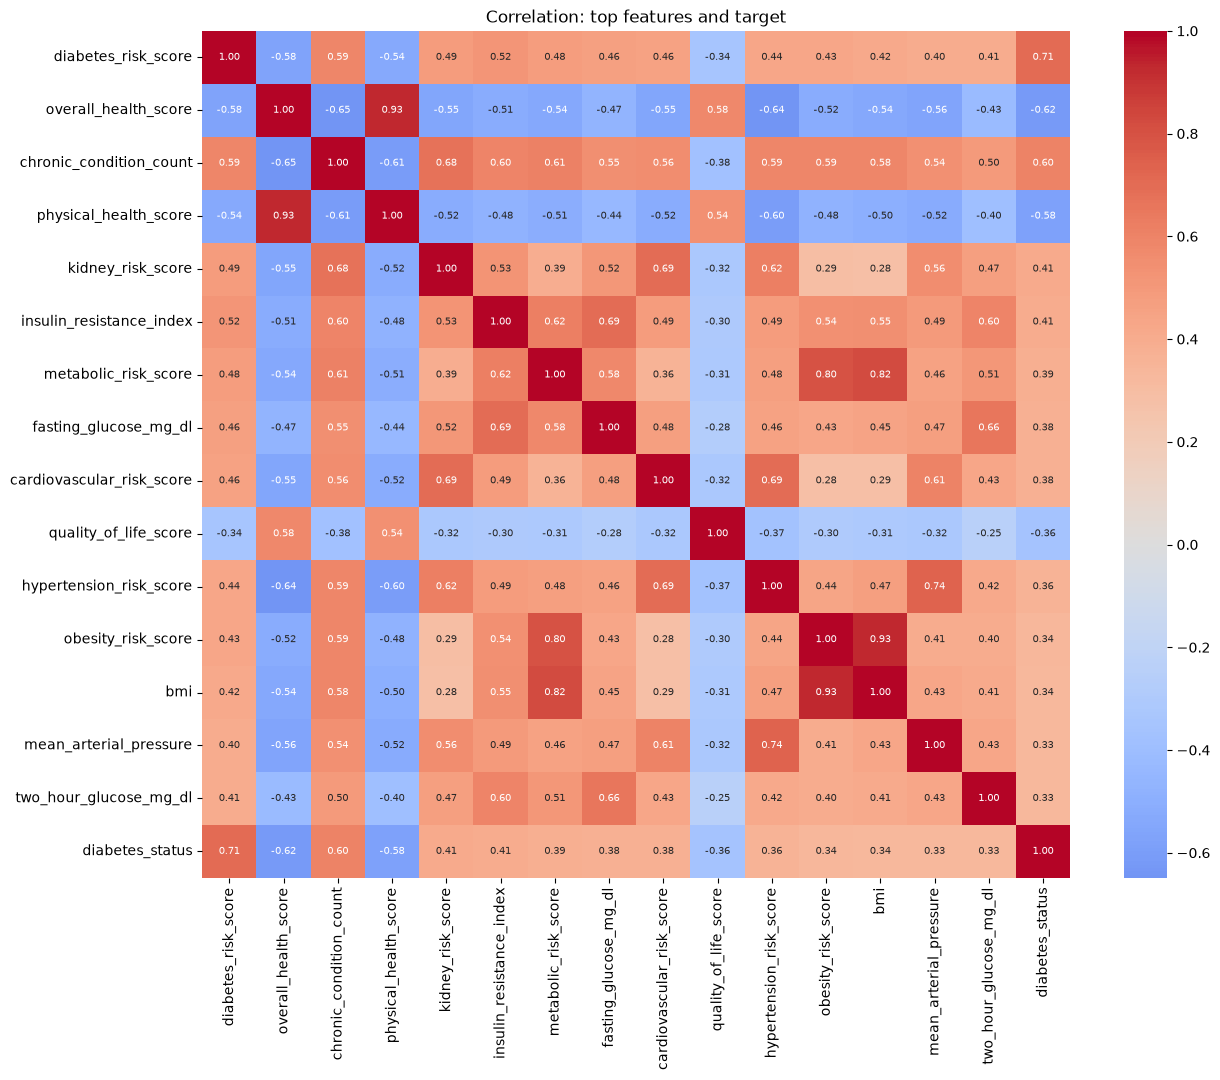

In [8]:
num_cols_d = d_complet.select_dtypes("number").columns.drop("diabetes_status").tolist()

target_corr = d_complet[num_cols_d].corrwith(d_complet["diabetes_status"]).sort_values(key=abs, ascending=False)
top_cols = target_corr.head(15).index.tolist() + ["diabetes_status"]
plt.figure(figsize=(14, 11))
sns.heatmap(d_complet[top_cols].corr(), cmap="coolwarm", center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation: top features and target")
plt.show()

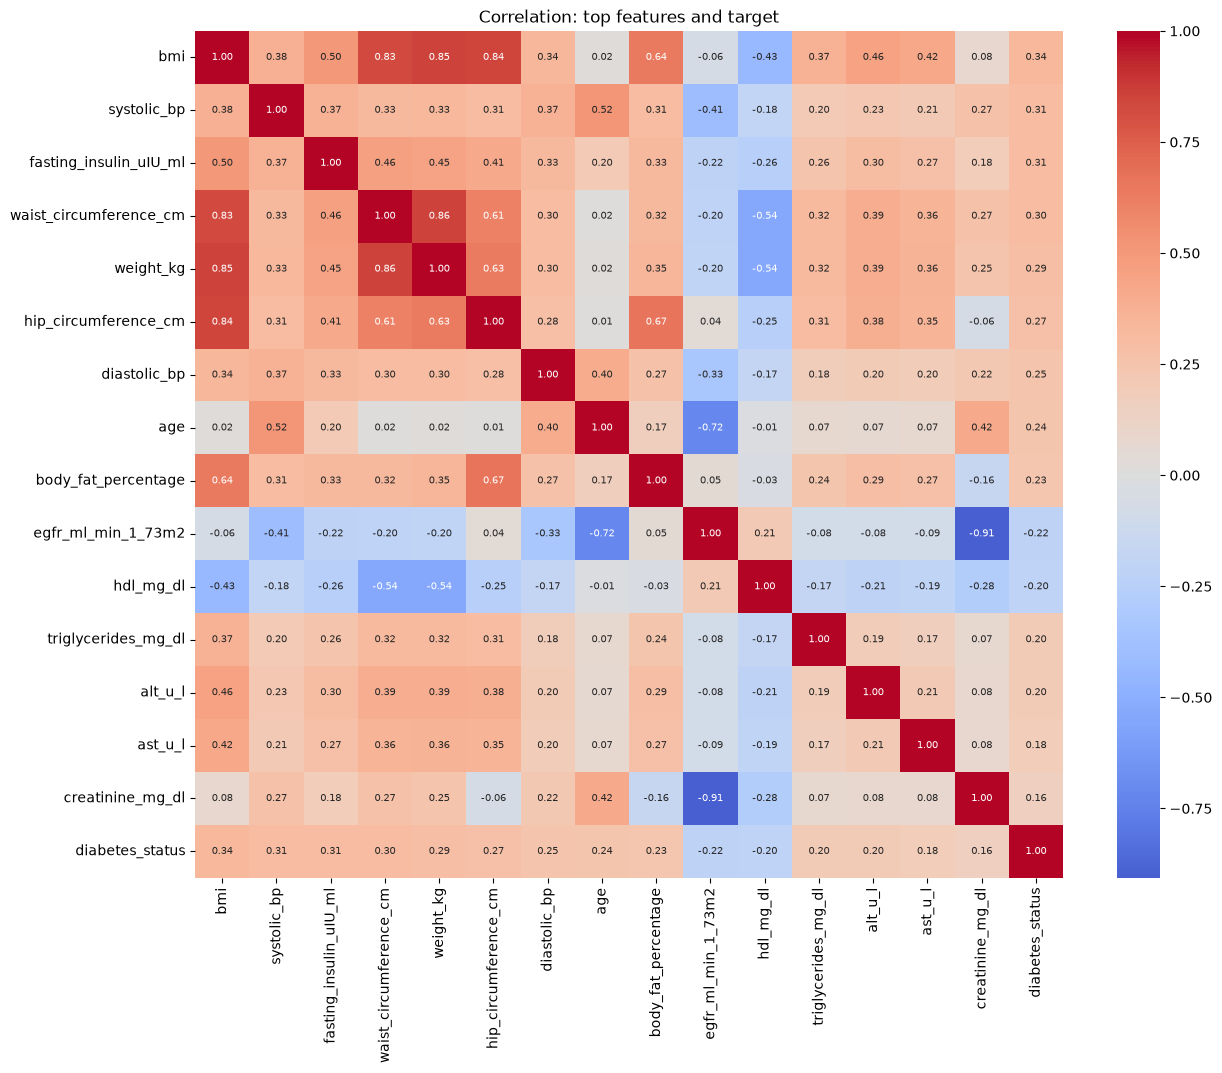

In [9]:
target_corr = diabete[num_cols].corrwith(diabete["diabetes_status"]).sort_values(key=abs, ascending=False)
top_cols = target_corr.head(15).index.tolist() + ["diabetes_status"]
plt.figure(figsize=(14, 11))
sns.heatmap(diabete[top_cols].corr(), cmap="coolwarm", center=0,
            annot=True, fmt=".2f", annot_kws={"size": 7})
plt.title("Correlation: top features and target")
plt.show()

## 2. Formatage des données : encodage des variables catégorielles et imputation des NaN

La fonction `Clean` construit un pipeline de prétraitement. Les colonnes sont réparties en 4 groupes :

| Groupe | Contenu | Traitement |
|---|---|---|
| `to_drop` | Colonnes constantes, doublons, fuites de données ou indisponibles au moment de la prédiction | Suppression |
| `binaires` | Variables à 2 modalités (Yes/No, Male/Female…) | `OrdinalEncoder` → 0/1 |
| `ordres` | Catégories avec un ordre logique | `OrdinalEncoder` avec l'ordre imposé (du plus faible au plus fort) → 0, 1, 2… |
| `onehot` | Catégories sans ordre | `OneHotEncoder(drop="first")` : une colonne 0/1 par modalité, moins une |

**Points d'attention**
- Les NaN restent des NaN à l'encodage (`encoded_missing_value=np.nan`). Une modalité inconnue dans un `ordres` devient NaN, et une erreur est levée si elle n'est pas dans la liste (garde-fou).

**Pipeline** (`ColumnTransformer` puis 3 étapes)
1. `ColumnTransformer` : applique l'encodage propre à chaque groupe. Les colonnes numériques passent telles quelles (`remainder="passthrough"`).
2. `IterativeImputer` : remplit tous les NaN du tableau, colonnes encodées comprises.
   - Initialisation des NaN avec la moyenne de la colonne.
   - Entraînement d'une régression (`BayesianRidge` par défaut) sur les lignes où la colonne est connue, avec les autres colonnes comme variables, puis prédiction des valeurs manquantes.
   - Opération répétée `max_iter=5` fois, en s'appuyant sur `n_nearest_features=30` colonnes tirées au hasard.
   - → *Paramètres à régler.*
3. Arrondi (option `arrondir=True`) : l'imputation produit des valeurs décimales. On arrondit les colonnes binaires et ordinales à l'entier le plus proche, borné aux modalités valides (0..1 pour les binaires, 0..k-1 pour les ordinales).
4. `StandardScaler` : centrage et réduction de toutes les colonnes.

**Éviter la fuite de données (data leakage)**
Les règles d'encodage et d'imputation sont apprises sur le train uniquement (`fit_transform`), puis appliquées au test (`transform`).

`Clean` peut renvoyer trois résultats :
- `explore=True` : le tableau transformé, pour l'exploration.
- `crossval=True` : le pipeline seul, à refitter dans chaque fold de la validation croisée.
- Par défaut : `X_train`, `X_test`, `y_train`, `y_test`, avec un split 80/20 (`random_state=42`).

`colonnes` (optionnel) impose une liste de colonnes, par exemple celles d'un niveau de sélection. Les listes d'encodage sont alors restreintes à ces colonnes et le split est stratifié sur la target.


### 2.1 Remplissage des NAs "logiques"
On commence par essayer de remplir de manière "logique" ce qui est possible.  
Par exemple, quand on a `pregnancy_status` = "Not Applicable", on sait que le patient est un homme, sinon une femme.

In [10]:

# --- sex : pregnancy_status == "Not Applicable" <=> Male, sans exception
print(pd.crosstab(diabete["sex"].fillna("NA"), diabete["pregnancy_status"].fillna("NA"), margins=True))
diabete["sex"] = diabete["sex"].fillna(pd.Series(
    np.where(diabete["pregnancy_status"] == "Not Applicable", "Male", "Female"), index=diabete.index))
print()
print(pd.crosstab(diabete["sex"].fillna("NA"), diabete["pregnancy_status"].fillna("NA"), margins=True))

# --- poids / taille / bmi : bmi = poids / taille² (écart max 0.005, dû aux arrondis) => chacun se déduit des deux autres
diabete["weight_kg"] = diabete["weight_kg"].fillna((diabete["bmi"] * (diabete["height_cm"] / 100) ** 2).round(1))
diabete["height_cm"] = diabete["height_cm"].fillna((100 * np.sqrt(diabete["weight_kg"] / diabete["bmi"])).round(1))
diabete["bmi"]       = diabete["bmi"].fillna((diabete["weight_kg"] / (diabete["height_cm"] / 100) ** 2).round(2))

# --- fumeur ? Current <=> cigarettes_per_day > 0 ; Never a toujours years_smoked == 0 donc années > 0 sans cigarette => Former
#     Reste ambigu : 0 cigarette et 0 année = Never (96,5 %) ou Former (3,5 %), laissé à l'imputer
sans_statut = diabete["smoking_status"].isna()
diabete["smoking_status"] = (diabete["smoking_status"]
                       .mask(sans_statut & (diabete["cigarettes_per_day"] > 0), "Current")
                       .mask(sans_statut & (diabete["cigarettes_per_day"] == 0) & (diabete["years_smoked"] > 0), "Former"))

# --- hospitalization_history | emergency_visit_history : remplace 4+ en 4
diabete["hospitalization_history"] = diabete["hospitalization_history"].replace("4+", "4").astype(int)
diabete["emergency_visit_history"] = diabete["emergency_visit_history"].replace("4+", "4").astype(int)

# --- pcos_status | gestational_diabetes_history : 3 catégories en OneHot (le "Not Applicable" est écrasé car ne caractérise que les hommes, info contenus dans `sex`)
diabete["pcos_status"] = (diabete["pcos_status"] == "Yes").astype(int)
diabete["gestational_diabetes_history"] = (diabete["gestational_diabetes_history"] == "Yes").astype(int)


pregnancy_status  Not Applicable  Not Pregnant  Postpartum  Pregnant    All
sex                                                                        
Female                         0         41806        2511      4854  49171
Male                       46845             0           0         0  46845
NA                           940           865          47       112   1964
All                        47785         42671        2558      4966  97980

pregnancy_status  Not Applicable  Not Pregnant  Postpartum  Pregnant    All
sex                                                                        
Female                         0         42671        2558      4966  50195
Male                       47785             0           0         0  47785
All                        47785         42671        2558      4966  97980


In [11]:
_, nombre_total_na, nombre_lignes_avec_na = calculer_stats_na(diabete, describe=False)
print(f"Nombre total de NaN : {nombre_total_na:,}")
diabete_sans_menaupose = diabete.drop(columns=["age_at_menopause"], errors="ignore")
_, _, nombre_lignes_avec_na = calculer_stats_na(diabete_sans_menaupose)
print(f"Nombre de lignes ayant au moins un NaN (sans menopause): {nombre_lignes_avec_na:,}")

Nombre total de NaN : 247,264
Nombre de lignes ayant au moins un NaN (sans menopause): 81,133


### 2.2 Impute des NAs restants et numérisation des colonnes catégorielles

In [ ]:
diabete.drop(columns=["age_at_menopause"], inplace=True, errors="ignore") # ~80% NaN, > 10.000 lignes uniquement nan ici
to_drop = ["diabetes_status"]             # Cible (y), à séparer de X

binaires = ["sex", "annual_checkup", "blood_pressure_medication", "statin_use",
    "family_history_diabetes", "family_history_cardiovascular_disease",
    "father_diabetes", "mother_diabetes", "sibling_diabetes",
    "family_history_hypertension", "family_history_obesity",
    "hypertension", "hyperlipidemia", "cardiovascular_disease", "coronary_artery_disease",
    "stroke_history", "kidney_disease", "liver_disease", "thyroid_disorder", "sleep_apnea",
    "metabolic_syndrome", "prediabetes_history", "cardiovascular_complication",
    "pcos_status", "gestational_diabetes_history"
    ]

ordres = {
"education_level": ["Less than High School","High School","Some College","Bachelor","Master","Doctorate"],
"neighborhood_income_level": ["Low","Lower-Middle","Middle","Upper-Middle","High"],
"fatty_liver_status": ["No","Possible","Yes"],
"smoking_status": ["Never","Former","Current"],
"physical_activity_level": ["Sedentary","Lightly Active","Moderately Active","Very Active","Extremely Active"],
"sleep_quality": ["Poor","Fair","Good","Excellent"],
"stress_level": ["Low","Moderate","High","Very High"],
"public_transport_access": ["Poor","Fair","Good","Excellent"],
"green_space_access": ["No","Limited","Yes"],
"residential_area_type": ["Rural","Suburban","Urban"],
"city_category": ["Rural","Small Town","Suburban","Urban","Metropolitan"],
"processed_food_frequency": ["Never","Rarely","Sometimes","Often","Daily"],
"fast_food_frequency": ["Never","Rarely","Sometimes","Often","Daily"],
"sugary_drink_frequency": ["Never","Rarely","Sometimes","Often","Daily"],
"breakfast_frequency": ["Never","Rarely","Sometimes","Often","Daily"],
"doctor_visit_frequency": ["Never","Yearly","Every 6 Months","Every 3 Months","Monthly"],
"alcohol_frequency": ["Never","Occasionally","Monthly","Weekly","Daily"]
}

onehot = ["ethnicity", "marital_status", "employment_status", "occupation_category",
        "diet_pattern", "pregnancy_status", "menopause_status",
        "country", "region", "state_province", "climate_zone", "insurance_status"
    ]

In [13]:
## Séparation Train / Test : On ne doit pas choisir la règles d'encodage ou de traitement des NA sur le Test
def Clean(d_temp, target, explore= False, crossval=False, colonnes=None, arrondir=True):  
    '''
    On prend toutes nos données
    Retrait des variables constantes, doublons, fuites de données et variables indisponibles au moment de la prédiction.  
    On prepare un Pipeline de traitement avec :
    - transformation des colonnes binaires chiffre 0/1
    - transformation des colonnes ordinales en {0,1,...,n}, NA rempli avec "most_frequent"
    - transformation du reste en plusieurs colonnes OneHot [0/1, ..., 0/1], 
    Puis on rempli tout les NA résiduels du tableau avec une régression linéaire

    `colonnes` (optionnel) : liste de colonnes imposées (ex. celles du niveau 2). Les listes d'encodage
    sont restreintes à ces colonnes, l'imputation utilise toutes ces colonnes, et le split train/test est
    stratifié (comme `donnees_niveau` de la partie 4, donc même jeu de test). Sans `colonnes`, comportement d'origine.
    '''

    df = d_temp.copy()
    if colonnes is None:                                     # comportement d'origine sur toutes les colonnes
        mask_target = df[target].notna()
        feature_cols = [colonne for colonne in df.columns if colonne not in to_drop]
        bin_cols, ord_dict, oh_cols = binaires, ordres, onehot
    else:                                                    # colonnes imposées après la sélection
        mask_target = df[target].notna()
        feature_cols = list(colonnes)
        bin_cols = [c for c in binaires if c in feature_cols]
        ord_dict = {c: v for c, v in ordres.items() if c in feature_cols}
        oh_cols = [c for c in onehot if c in feature_cols]

    X = df.loc[mask_target, feature_cols].copy()
    y = df.loc[mask_target, target].copy()

    ## Traitement des NA
    ord_cols = list(ord_dict)

    # Garde-fou : une modalité absente de `ordres` serait silencieusement transformée en NaN
    for c in ord_cols:
        inconnues = set(X[c].dropna().unique()) - set(ord_dict[c])
        if inconnues:
            raise ValueError(f"{c} : modalités absentes de `ordres` -> {inconnues}")

    cat = ColumnTransformer([
        ("bin", OrdinalEncoder(encoded_missing_value=np.nan), bin_cols),
        ("ord", OrdinalEncoder(categories=[ord_dict[c] for c in ord_cols],
                               handle_unknown="use_encoded_value",
                               unknown_value=np.nan,
                               encoded_missing_value=np.nan), ord_cols),
        ("oh", OneHotEncoder(drop="first", handle_unknown="ignore",
                             sparse_output=False), oh_cols),
    ], remainder="passthrough", verbose_feature_names_out=False).set_output(transform="pandas")

    # Bornes valides des colonnes encodées en entiers (binaires : 0..1, ordinales : 0..k-1)
    bornes = {c: (0, 1) for c in bin_cols}
    bornes.update({c: (0, len(ord_dict[c]) - 1) for c in ord_cols})

    etapes = [("cat", cat),
              ("imp", IterativeImputer(max_iter=5, n_nearest_features=30, random_state=42))]
    
    if arrondir:
        etapes.append(("round", ArrondirModalites(bornes=bornes)))
    
    etapes.append(("scale", StandardScaler()))
    prep = Pipeline(etapes).set_output(transform="pandas")
    
    if explore:                        # On veut juste explorer les données, pas de split train/test ni d'encodage du target
        df = prep.fit_transform(X)
        return df
    
    else:
        if crossval:    # Returne le pipeline de traitement, à réutiliser dans chaque boucle de cross-validation pour éviter le DataLeak
            return prep

        else:           # Sinon on applique direct le traitement et on rend les données splitées en train/test
            X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
            X_train_1 = prep.fit_transform(X_train)   # apprend et applique sur le train
            X_test_1  = prep.transform(X_test)        # applique sur le test

            return X_train_1, X_test_1, y_train, y_test

In [14]:
# Durée 10s
X_train, X_test, y_train, y_test = Clean(diabete, target="diabetes_status", explore=False, crossval=False, arrondir=True)

### 2.3 Bilan de l'imputation  
On vérifie que le nettoyage (remplissage des NAs + encodage + imputation) n'a pas déformé les données, en comparant :
- avant / après le `Clean`
- train / test : le pipeline est ajusté sur le train puis appliqué sur train et test. Il faut vérifier qu'on a pas de "sur-apprentissage" qui fausserai le transform sur le test

In [15]:
# Durée 10s
# --- Même découpage que Clean (mêmes lignes, même random_state) : données BRUTES, puis imputées SANS StandardScaler
X = diabete.drop("diabetes_status", axis=1)
y = diabete["diabetes_status"]
X_train_brut, X_test_brut, y_train_brut, y_test_brut = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)
assert X_train_brut.index.equals(X_train.index) and X_test_brut.index.equals(X_test.index)

prep = Clean(diabete, target="diabetes_status", crossval=True)    # pipeline non ajusté
prep_sans_scaler = prep[:-1]                                      # encodage + imputation, sans StandardScaler
X_train_imp = prep_sans_scaler.fit_transform(X_train_brut)        # ajusté sur le train uniquement
X_test_imp = prep_sans_scaler.transform(X_test_brut)

**Verification rapide : on a bien combler tout les NAs**

In [16]:
na_train, total_train, lignes_train = calculer_stats_na(X_train_brut)
na_test, total_test, lignes_test = calculer_stats_na(X_test_brut)

resume_na = pd.DataFrame({
    "NaN avant": [total_train, total_test],
    "lignes avec NaN avant": [lignes_train, lignes_test],
    "NaN après": [int(X_train_imp.isna().sum().sum()), int(X_test_imp.isna().sum().sum())]},
    index=["train", "test"])
display(resume_na)

,NaN avant,lignes avec NaN avant,NaN après
train,133154,64841,0
test,33494,16292,0


**Contrôle de l'imputation : les colonnes qui avaient des NaN**

Pour ces colonnes, on compare la distribution **avant** imputation (valeurs observées) et **après** imputation (valeurs observées + valeurs imputées). L'imputation ne doit pas déformer les données : on veut conserver la moyenne, l'écart-type et la répartition, sans créer de valeurs hors bornes.

| Indicateur | Ce qu'il mesure | Lecture |
|---|---|---|
| **SMD** (Standardized Mean Difference) | Écart des moyennes avant/après, en nombre d'écarts-types : (moyenne après − moyenne avant) / écart-type | Proche de 0 = moyenne conservée. Seuil usuel : \|SMD\| < 0,1 |
| **KS** (Kolmogorov-Smirnov) | Écart maximal entre les deux fonctions de répartition (CDF), donc la forme globale de la distribution | Entre 0 et 1. Proche de 0 = même distribution |
| **TV** (Total Variation) | Différence entre les fréquences de chaque modalité avant/après : ½ · Σ \|pᵢ − qᵢ\| | Entre 0 et 1. Proche de 0 = mêmes proportions. Adapté aux variables catégorielles ou binaires |
| **Bornes** | Valeurs minimales et maximales après imputation | Doivent rester dans l'intervalle valide (0..1 pour les binaires, 0..k-1 pour les ordinales) |

**En résumé**
- SMD → la moyenne (et la dispersion) a-t-elle bougé ?
- KS → la forme de la distribution a-t-elle bougé (variables ordinales/numériques) ?
- TV → les proportions de chaque modalité ont-elles bougé (variables catégorielles) ?
- Bornes → l'imputation a-t-elle inventé des valeurs impossibles ?


In [17]:
# ---------- Colonnes concernées : celles qui avaient des NA avant imputation (train ou test) ----------
cols_num = X_train_brut.select_dtypes("number").columns
cols_num_na = [c for c in cols_num if X_train_brut[c].isna().any() or X_test_brut[c].isna().any()]
cat_na = [c for c in ordres if c in X_train_brut.columns
          and (X_train_brut[c].isna().any() or X_test_brut[c].isna().any())]

# ---------- Numériques : SMD + KS ----------
def deformation_num(brut, imp):
    lignes = {}
    for c in cols_num_na:
        a, b = brut[c].dropna(), imp[c].dropna()
        lignes[c] = {
            "NA_%": 100 * brut[c].isna().mean(),
            "SMD": (b.mean() - a.mean()) / a.std(),   # décalage de la moyenne, en σ
            "KS": ks_2samp(a, b).statistic,           # écart global entre distributions (0 = identiques)
        }
    return pd.DataFrame(lignes).T

# ---------- Catégorielles : TV ----------
def parts(serie, modalites):
    return serie.value_counts(normalize=True).reindex(modalites).fillna(0).mul(100)

def deformation_cat(brut, imp):
    lignes = {}
    for c in cat_na:
        modalites = ordres[c]
        decode = dict(enumerate(modalites))                       # code ordinal -> modalité
        p = parts(brut[c], modalites)                             # avant (hors NA)
        q = parts(imp[c].round().astype(int).map(decode), modalites)  # après imputation
        lignes[c] = {
            "NA_%": 100 * brut[c].isna().mean(),
            "TV_%": 0.5 * (p - q).abs().sum(),                    # % des données ayant changé de modalité
        }
    return pd.DataFrame(lignes).T

# ---------- Modalités : mêmes catégories avant / après imputation ? ----------
# Binaires : codes {0,1} ; ordinales : codes {0..k-1}. On compare les ensembles de codes présents.
def modalites_avant(serie, c):
    if c in ordres:
        return {ordres[c].index(m) for m in serie.dropna().unique()}   # modalité -> code ordinal
    return set(range(serie.nunique()))                                  # binaire : codes 0..n-1

def test_modalites(brut, imp):
    lignes = {}
    for c in cat_na:
        avant = modalites_avant(brut[c], c)
        apres = set(imp[c].dropna().round().astype(int).unique())
        lignes[c] = {
            "NA_%": 100 * brut[c].isna().mean(),
            "avant": sorted(avant),
            "après": sorted(apres),
            "apparues": sorted(apres - avant),      # nouvelles modalités créées par l'imputation
            "disparues": sorted(avant - apres),     # modalités perdues
            "OK": apres == avant,
        }
    return pd.DataFrame(lignes).T

# ---------- Train et test côte à côte ----------
def train_vs_test(fonction, tri):
    res = pd.concat({"train": fonction(X_train_brut, X_train_imp),
                     "test": fonction(X_test_brut, X_test_imp)}, axis=1)
    return res.sort_values(("train", tri), ascending=False)

# ---------- Application ----------
print("Numériques (colonnes avec NA avant imputation)")
display(train_vs_test(deformation_num, "KS").round(3))

print("Catégorielles (colonnes avec NA avant imputation)")
display(train_vs_test(deformation_cat, "TV_%").round(2))

print("Modalités avant/après imputation (colonnes binaires et ordinales avec NA)")
for nom, brut, imp in [("train", X_train_brut, X_train_imp), ("test", X_test_brut, X_test_imp)]:
    res = test_modalites(brut, imp)
    print(f"{nom} : {res['OK'].sum()}/{len(res)} colonnes avec les mêmes modalités")
    display(res[~res["OK"].astype(bool)])    # n'affiche que les colonnes problématiques (vide = tout est bon)


Numériques (colonnes avec NA avant imputation)


train                  test              
                           NA_%    SMD     KS    NA_%    SMD     KS
vitamin_b12_pg_ml         9.895  0.000  0.050   9.951  0.000  0.050
folate_ng_ml             10.068 -0.000  0.050   9.997  0.000  0.050
vitamin_d_ng_ml          10.096 -0.000  0.049   9.701  0.000  0.048
urine_albumin_mg_g       10.167  0.000  0.038   9.997  0.000  0.037
ferritin_ng_ml            9.955 -0.000  0.034  10.191  0.000  0.035
c_peptide_ng_ml           9.978  0.000  0.031   9.890 -0.001  0.031
wbc_count                 5.076  0.000  0.025   4.761 -0.001  0.024
platelet_count            4.842  0.000  0.024   4.955  0.000  0.025
sleep_hours               4.947  0.000  0.024   5.088  0.000  0.025
hemoglobin_g_dl           5.081  0.001  0.016   5.226  0.000  0.017
fasting_insulin_uIU_ml   10.147  0.000  0.014  10.303 -0.003  0.014
triglycerides_mg_dl       5.032  0.000  0.013   5.139 -0.000  0.012
alt_u_l                   5.033 -0.000  0.011   4.894  0.001  0.010
ast_u_l                   5.043  0.001  0.010   5.037  0.000  0.011
hdl_mg_dl                 5.015 -0.001  0.005   4.756  0.002  0.005
diastolic_bp              2.086  0.000  0.003   2.097  0.001  0.004
creatinine_mg_dl          5.047  0.000  0.003   4.731 -0.000  0.004
total_cholesterol_mg_dl   5.005 -0.001  0.003   5.052  0.004  0.004
ldl_mg_dl                 4.981 -0.000  0.003   5.083 -0.002  0.005
egfr_ml_min_1_73m2        4.969  0.000  0.003   5.220 -0.000  0.003
systolic_bp               1.957  0.000  0.002   1.873 -0.001  0.002
waist_circumference_cm    5.118  0.002  0.002   5.088 -0.002  0.002
hip_circumference_cm      4.902  0.000  0.002   5.414  0.002  0.003
age                       1.985  0.000  0.001   2.026 -0.001  0.002
weight_kg                 0.343 -0.000  0.001   0.367 -0.000  0.001
height_cm                 0.315  0.000  0.000   0.332 -0.001  0.000
bmi                       0.170  0.000  0.000   0.240 -0.001  0.000

Catégorielles (colonnes avec NA avant imputation)


train         test      
                         NA_%  TV_%   NA_%  TV_%
public_transport_access  9.90  6.61  10.42  6.86
stress_level             4.89  2.93   4.94  2.98
smoking_status           2.88  1.34   2.95  1.35
physical_activity_level  4.95  0.63   5.21  0.68

Modalités avant/après imputation (colonnes binaires et ordinales avec NA)
train : 4/4 colonnes avec les mêmes modalités


,NA_%,avant,après,apparues,disparues,OK


test : 4/4 colonnes avec les mêmes modalités


,NA_%,avant,après,apparues,disparues,OK


## 3. Premier modèle naïf
### 3.1 Detection de dataleak

In [18]:
# Durée 2min
def en_category(df):
    """Seule transformation technique : texte -> category (lu nativement par XGBoost)."""
    df = df.infer_objects()
    return df.astype({c: "category" for c in df.select_dtypes(["object", "string"]).columns})

def xgb():
    return XGBClassifier(n_jobs=-1, random_state=SEED, eval_metric="logloss",
                         tree_method="hist", enable_categorical=True,
                         n_estimators=150, importance_type="gain")

N_MAX = 30                 # nombre de colonnes retirées au maximum
SEED = 42

# --- Jeu 1 : dataset entier, rechargé : aucune colonne supprimée, aucune imputation
m1 = d_complet["diabetes_status"].notna()
y_1 = d_complet.loc[m1, "diabetes_status"].astype(int)
X_1 = en_category(d_complet.loc[m1].drop(columns=["diabetes_status", "patient_id", "record_id"], errors="ignore"))

# --- Jeu 2 : après le drop des colonnes problématiques, valeurs brutes (NaN conservés)
colonnes_apres_drop = [c for c in diabete.columns if c not in to_drop]     # to_drop = cible + age_at_menopause
X_2 = en_category(d_complet.loc[diabete.index, colonnes_apres_drop])
y_2 = d_complet.loc[diabete.index, "diabetes_status"].astype(int)

# --- Jeu 3 : après le Clean (remplissage logique + encodage + imputation + scaler), refait dans chaque pli
prep_complet = Clean(diabete, target="diabetes_status", crossval=True)
X_3 = diabete.loc[:, colonnes_apres_drop]
y_3 = diabete["diabetes_status"].astype(int)

# --- Détection de fuites : retrait glouton de la colonne la plus importante
X_tr, X_va, y_tr, y_va = train_test_split(X_1, y_1, test_size=0.2, stratify=y_1, random_state=SEED)

colonnes = list(X_tr.columns)
trace = []
for etape in range(N_MAX + 1):
    m = xgb().fit(X_tr[colonnes], y_tr)
    p = m.predict_proba(X_va[colonnes])[:, 1]
    imp = pd.Series(m.feature_importances_, index=colonnes).sort_values(ascending=False)
    retiree = imp.index[0]
    trace.append({
        "etape": etape,
        "retiree": trace and retiree or "(aucune)",
        "AUC": roc_auc_score(y_va, p),
        "F1": f1_score(y_va, (p >= 0.5).astype(int)),
    })
    colonnes.remove(retiree)
courbe = pd.DataFrame(trace)

# --- Colonnes de fuite, déterminées par la courbe de retrait glouton (chute de 1.000 à 0.830)
colonnes_leak = [
    "diabetes_type", "diabetes_risk_score",
    "overall_health_score", "physical_health_score",
    "fasting_glucose_mg_dl", "previous_diabetes_diagnosis",
    "chronic_condition_count",
]
AJOUTER_PAR_PRINCIPE = False     # True : retire aussi hba1c_percent (critère diagnostique, hors top 30)
if AJOUTER_PAR_PRINCIPE:
    colonnes_leak = colonnes_leak + ["hba1c_percent"]

# --- Jeu 1b : dataset entier moins les seules colonnes de fuite
X_1b = X_1.drop(columns=colonnes_leak, errors="ignore")
y_1b = y_1

jeux = {
    "1. Dataset entier":               (X_1,  y_1,  xgb()),
    "1b. Moins les colonnes de fuite": (X_1b, y_1b, xgb()),
    "2. Après drop des colonnes":      (X_2,  y_2,  xgb()),
    "3. Après fonction Clean()":                  (X_3,  y_3,  Pipeline([("prep", prep_complet), ("xgb", xgb())])),
}

# --- Validation croisée (mêmes plis pour tous les jeux)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
scoring = {"AUC": "roc_auc", "F1": "f1", "AP": "average_precision"}

resultats_fuite = {}
for nom, (X, y, modele) in jeux.items():
    r = cross_validate(clone(modele), X, y, cv=cv, scoring=scoring, n_jobs=1)
    resultats_fuite[nom] = {m: r[f"test_{m}"] for m in scoring}

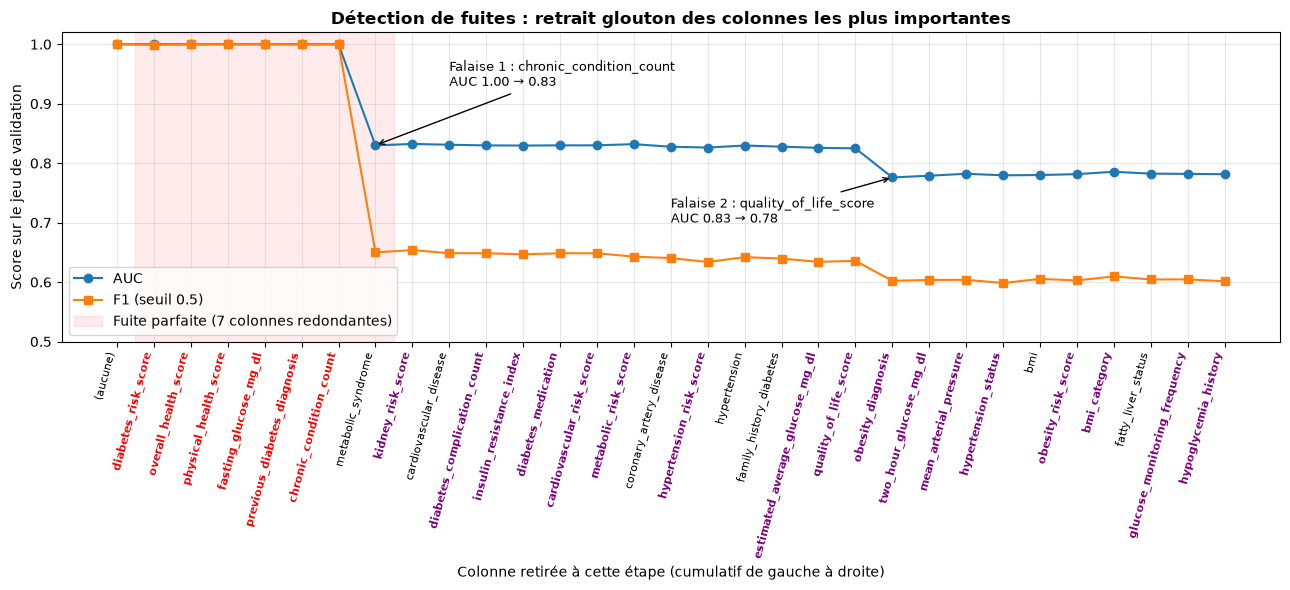

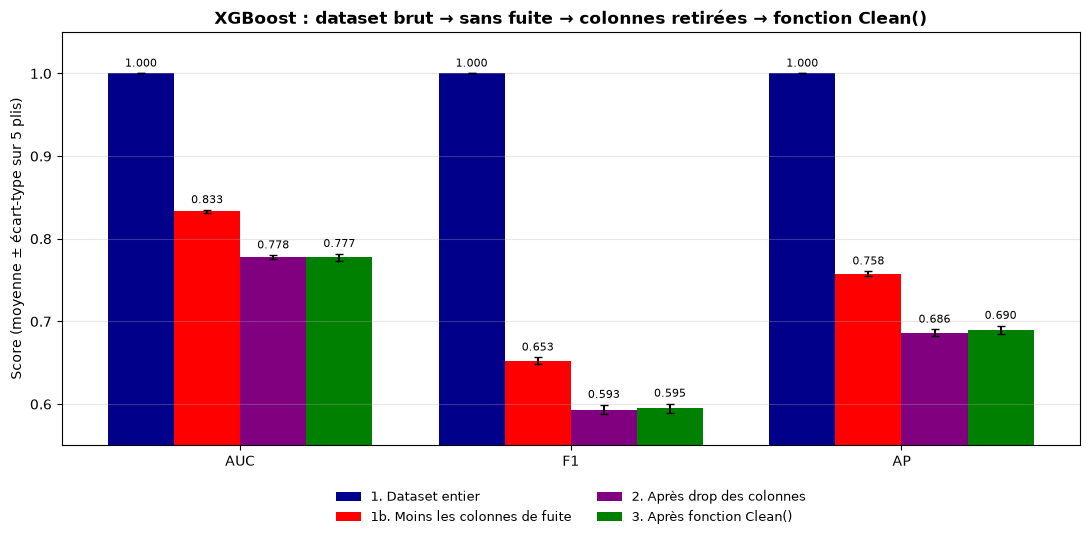

In [19]:
# --- Graphique 1 : détection de fuites, avec la falaise annotée
fig, ax = plt.subplots(figsize=(13, 6))
ax.plot(courbe["etape"], courbe["AUC"], "o-", label="AUC")
ax.plot(courbe["etape"], courbe["F1"], "s-", label="F1 (seuil 0.5)")
ax.set_xticks(courbe["etape"])
ax.set_xticklabels(courbe["retiree"], rotation=75, ha="right", fontsize=8)
colonnes_drop = set(d_complet.columns) - set(diabete.columns)     # colonnes retirées par le .drop de la cellule 6
for label in ax.get_xticklabels():
    if label.get_text() in colonnes_fuite:
        label.set_color("red")
        label.set_fontweight("bold")
    if label.get_text() in colonnes_drop and label.get_text() not in colonnes_fuite:
        label.set_color("purple")
        label.set_fontweight("bold")
ax.set_ylim(0.5, 1.02)
ax.axvspan(0.5, 7.5, color="red", alpha=0.08, label="Fuite parfaite (7 colonnes redondantes)")
ax.annotate("Falaise 1 : chronic_condition_count\nAUC 1.00 → 0.83",
            xy=(7, 0.83), xytext=(9, 0.93), arrowprops={"arrowstyle": "->"}, fontsize=9)
ax.annotate("Falaise 2 : quality_of_life_score\nAUC 0.83 → 0.78",
            xy=(21, 0.776), xytext=(15, 0.70), arrowprops={"arrowstyle": "->"}, fontsize=9)
ax.set_xlabel("Colonne retirée à cette étape (cumulatif de gauche à droite)")
ax.set_ylabel("Score sur le jeu de validation")
ax.set_title("Détection de fuites : retrait glouton des colonnes les plus importantes", fontweight="bold")
ax.grid(alpha=0.3)
ax.legend(loc="lower left")
plt.tight_layout()
plt.savefig("save/courbe_dataleak.png", dpi=300, bbox_inches="tight")
plt.show()

# --- Graphique 2 : récap des 4 jeux
metriques = list(scoring)
noms = list(resultats_fuite)
couleurs = ["darkblue", "red", "purple", "green"]
largeur = 0.8 / len(noms)
x = np.arange(len(metriques))

fig, ax = plt.subplots(figsize=(11, 5.5))
for i, nom in enumerate(noms):
    moy = [resultats_fuite[nom][m].mean() for m in metriques]
    ecart = [resultats_fuite[nom][m].std() for m in metriques]
    barres = ax.bar(x + i * largeur, moy, largeur, yerr=ecart, capsize=3, label=nom, color=couleurs[i])
    ax.bar_label(barres, fmt="%.3f", padding=3, fontsize=8)

ax.set_xticks(x + largeur * (len(noms) - 1) / 2)
ax.set_xticklabels(metriques)
ax.set_ylim(0.55, 1.05)
ax.set_ylabel("Score (moyenne ± écart-type sur 5 plis)")
ax.set_title("XGBoost : dataset brut → sans fuite → colonnes retirées → fonction Clean()", fontweight="bold")
ax.legend(loc="upper center", ncol=2, fontsize=9, frameon=False, bbox_to_anchor=(0.5, -0.08))
ax.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("save/recap_etapes_xgboost.png", dpi=300, bbox_inches="tight")
plt.show()

### 3.2 Première perf de modèle :  
|Modèle|Initiallement|Après Standardisation (StandardScaler)|
|---|:---:|:---:|
|Logistic Regression|0.4503|0.6176|
|GaussianNB|0.5905|0.6070|
|LinearSVC|0.5670|0.6033|
|XGBClassifier|0.6105|0.6105|

- diabete : data set  
- X_train_brute : découpage du data set  
- X_train_imp : passé dans le prep SANS le `StandardScaler()`  
- X_train : passé dans prep entier  
- y_train, y_train_brute ... sont tous égaux, on ne touche jamais rien a part le découpage qui est identique

c:\cours_code\Python\Enviro\venv\ml-deep\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(
c:\cours_code\Python\Enviro\venv\ml-deep\Lib\site-packages\sklearn\linear_model\_logistic.py:599: ConvergenceWarning: lbfgs failed to converge after 100 iteration(s) (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT

Increase the number of iterations to improve the convergence (max_iter=100).
You might also want to scale the data as shown in:
    https://scikit-learn.org/stable/modules/p

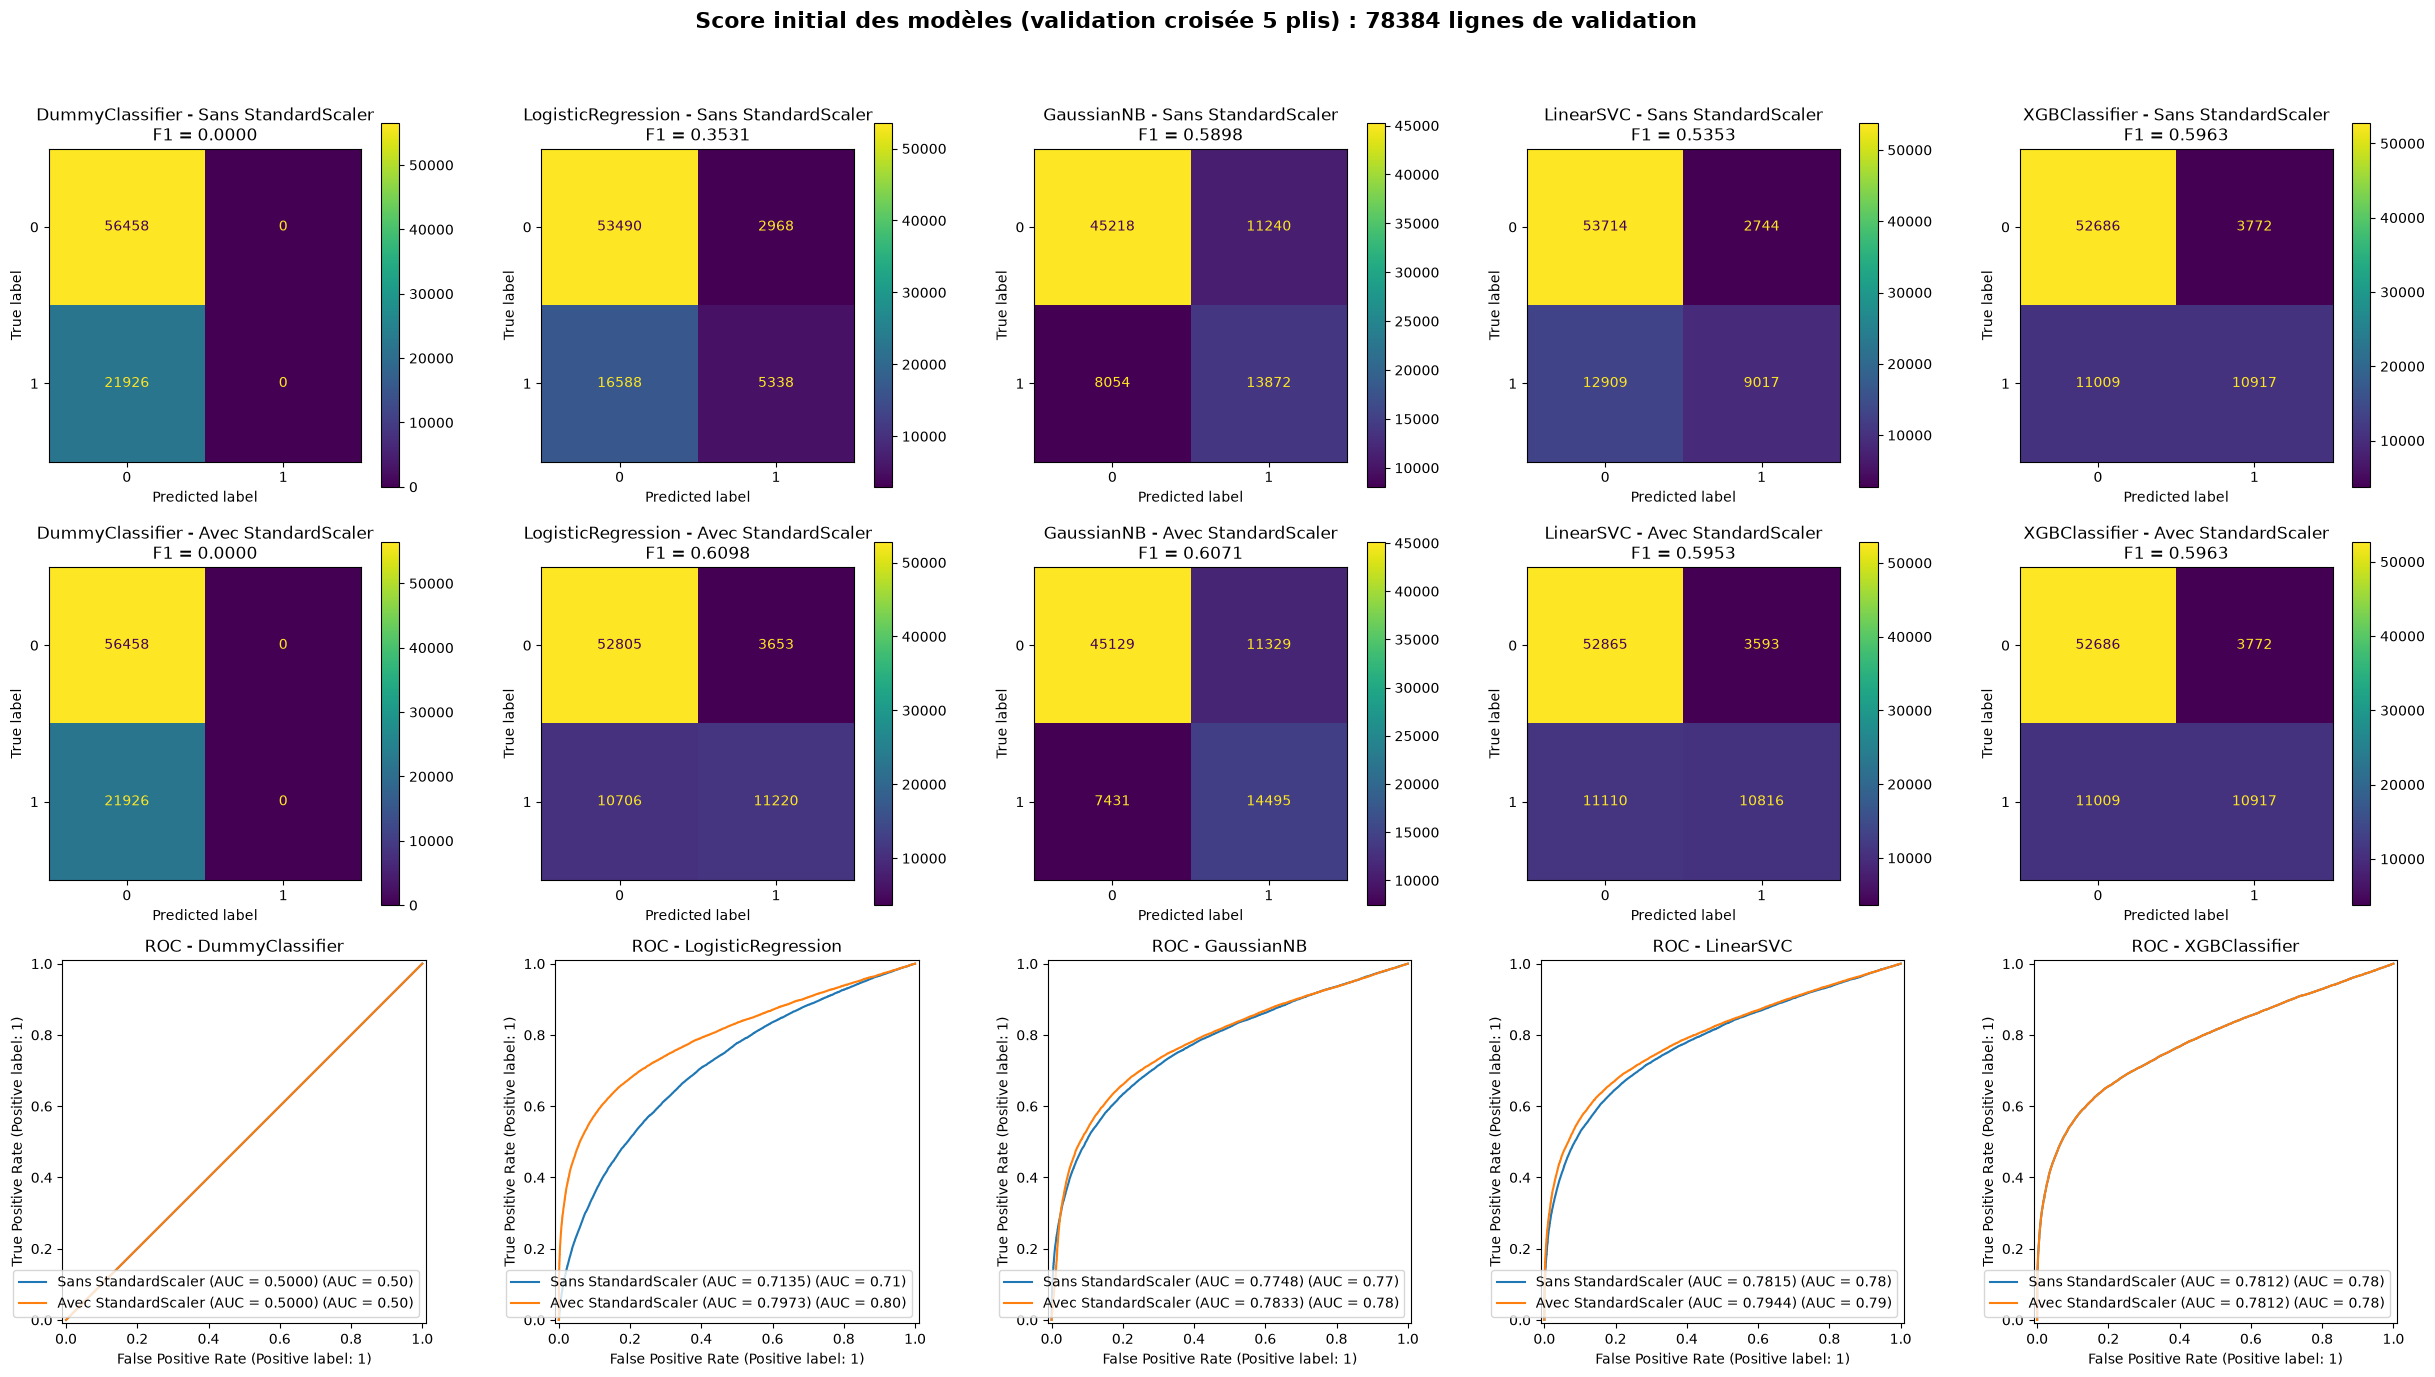

In [20]:
# Durée 1min
variantes = ["Sans StandardScaler", "Avec StandardScaler"]

mod = [DummyClassifier, LogisticRegression, GaussianNB, LinearSVC, XGBClassifier]

predict_score = [
    lambda m, X: m.predict_proba(X)[:, 1],
    lambda m, X: m.predict_proba(X)[:, 1],
    lambda m, X: m.predict_proba(X)[:, 1],
    lambda m, X: m.decision_function(X),
    lambda m, X: m.predict_proba(X)[:, 1]
]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
prep = Clean(diabete, target="diabetes_status", crossval=True)
prep_s_sc = prep[:-1]  # encodage + imputation, sans StandardScaler
prep_j_sc = prep[-1]   # StandardScaler

# Prédictions sur les plis de validation : pour chaque variante et chaque modèle, une liste (un élément par pli)
yhat_mod = {v: [[] for _ in mod] for v in variantes}
yscore_mod = {v: [[] for _ in mod] for v in variantes}
y_oof = []

for train_index, test_index in cv.split(X_train_brut, y_train_brut):
    X_train_fold, X_test_fold = X_train_brut.iloc[train_index], X_train_brut.iloc[test_index]
    y_train_fold, y_test_fold = y_train_brut.iloc[train_index], y_train_brut.iloc[test_index]
    y_oof.append(y_test_fold)

    # Prétraitement appris sur le train du pli, puis appliqué au pli de validation
    x_sc_train = prep_s_sc.fit_transform(X_train_fold)
    x_sc_test = prep_s_sc.transform(X_test_fold)
    x_train = prep_j_sc.fit_transform(x_sc_train)
    x_test = prep_j_sc.transform(x_sc_test)

    donnees = {
        "Sans StandardScaler": (x_sc_train, x_sc_test),
        "Avec StandardScaler": (x_train, x_test),
    }

    for i, (name, score_func) in enumerate(zip(mod, predict_score)):
        for v, (X_tr, X_te) in donnees.items():
            m = name()
            m.fit(X_tr, y_train_fold)
            yhat_mod[v][i].append(m.predict(X_te))
            yscore_mod[v][i].append(score_func(m, X_te))

# Un seul vecteur par modèle : les 5 plis de validation mis bout à bout (même ordre que y_oof)
y_oof = np.concatenate(y_oof)
yhat_mod = {v: [np.concatenate(p) for p in yhat_mod[v]] for v in variantes}
yscore_mod = {v: [np.concatenate(p) for p in yscore_mod[v]] for v in variantes}

n_modeles = len(mod)

fig, axes = plt.subplots(
    3, n_modeles,
    figsize=(5 * n_modeles, 14)
)

axes = np.atleast_2d(axes)

# Lignes 1 et 2 : matrices de confusion (sans puis avec StandardScaler)
for ligne, v in enumerate(variantes):
    for i, yhat in enumerate(yhat_mod[v]):
        cm = confusion_matrix(y_oof, yhat)
        ConfusionMatrixDisplay(confusion_matrix=cm).plot(ax=axes[ligne, i], colorbar=True)
        axes[ligne, i].set_title(f"{mod[i].__name__} - {v}\nF1 = {f1_score(y_oof, yhat):.4f}")

# Ligne 3 : courbes ROC des deux variantes superposées
for i in range(n_modeles):
    for v, style in zip(variantes, ["-", "--"]):
        yscore = yscore_mod[v][i]
        auc = roc_auc_score(y_oof, yscore)
        RocCurveDisplay.from_predictions(y_oof, yscore, ax=axes[2, i],
                                         name=f"{v} (AUC = {auc:.4f})")
    axes[2, i].set_title(f"ROC - {mod[i].__name__}")

fig.suptitle(f"Score initial des modèles (validation croisée {cv.get_n_splits()} plis) : {len(y_oof)} lignes de validation", fontsize=16, fontweight="bold")

plt.savefig("save/score_mod_initial_versus.png", dpi=300, bbox_inches="tight")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

## 4. Selection des variables & Optimisation des hyperparamètres


### 4.1 Debut bancal

In [21]:
### Durée 3min30
### 1. Filtre indépendant du modèles, dépendants uniquement des données : Attention au dataleak
memoire = Memory("cache_prep", verbose=0) # évite de refaire l'imputation pour chaque modèle

# --- Ton découpage (inchangé) ---
X = diabete.drop("diabetes_status", axis=1)
y = diabete["diabetes_status"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=42)

cv = StratifiedKFold(n_splits=8, shuffle=True, random_state=42)

continues = [c for c in X_train.columns if c not in binaires + list(ordres) + onehot]

# --- Les variantes de filtre à comparer ---
variantes = {
    "base": {},
    "corr_feat 0.95":       {'corr_feat': 0.95},
    "const 0.98":           {'const_share': 0.98},
    "corr_y 0.02":          {'corr_y': 0.02},
    "corr_y 0.05":          {'corr_y': 0.05},
    "corr_y 0.10":          {'corr_y': 0.10},
    "tout":                 {'corr_feat': 0.95, 'const_share': 0.98, 'corr_y': 0.05}
}

prep = Clean(diabete, target="diabetes_status", crossval=True)    # pipeline non ajusté

def evaluate(model, filtre_kw):
    pipe = Pipeline([("prep", prep),
                     ("filter", ColumnFilter(**filtre_kw)),
                     ("model", model)], memory=memoire)            # plus de memory=memoire
    res = cross_validate(pipe, X_train, y_train, cv=cv, n_jobs=-1, return_estimator=True,
                         scoring=["f1", "roc_auc", "average_precision"])

    filtres = [e.named_steps["filter"] for e in res.pop("estimator")]
    n_ret = np.mean([len(f.drop_) for f in filtres])
    n_in = np.mean([f.n_in_ for f in filtres])
    out = pd.DataFrame(res)
    out["n_retirees"] = n_ret
    out["n_col"] = n_in - n_ret
    return out

mod = [LogisticRegression, GaussianNB, LinearSVC, XGBClassifier]

# --- Cache des résultats (comme pour la sélection de colonnes) ---
RECALCULER_FILTRES = False       # True = tout refaire
FICHIER_FILTRES = Path("cache_selection") / "resultats_filtres.joblib"
FICHIER_FILTRES.parent.mkdir(exist_ok=True)

# Tout ce qui change les résultats : si un de ces éléments change, le cache est ignoré
contexte = {'to_drop': sorted(to_drop), 'binaires': list(binaires), 'ordres': dict(ordres), 'onehot': list(onehot),
                'n_train': len(X_train), 'n_splits': cv.get_n_splits()}
    
cache = {}
if FICHIER_FILTRES.exists() and not RECALCULER_FILTRES:
    sauvegarde = joblib.load(FICHIER_FILTRES)
    if sauvegarde["contexte"] == contexte:
        cache = sauvegarde["entrees"]
        print(f"{len(cache)} résultats rechargés depuis {FICHIER_FILTRES.name}")
    else:
        print("cache ignoré : to_drop, listes d'encodage ou découpage ont changé")

def evaluate_cache(nom_modele, nom_filtre, model, filtre_kw):
    cle = (nom_modele, nom_filtre)
    if cle in cache and cache[cle]["filtre_kw"] == filtre_kw:
        return cache[cle]["res"]
    res = evaluate(model, filtre_kw)
    cache[cle] = {'filtre_kw': filtre_kw, 'res': res}
    joblib.dump({'contexte': contexte, 'entrees': cache}, FICHIER_FILTRES)   # sauvegarde après chaque calcul : reprise possible
    return res


resultats = {}
resultats[("DummyClassifier", "base")] = evaluate_cache("DummyClassifier", "base", DummyClassifier(), {})
for model in mod:
    for nom, kw in variantes.items():
        resultats[(model.__name__, nom)] = evaluate_cache(model.__name__, nom, model(), kw)

# --- Tableau récapitulatif (écart d'AUC apparié, pli par pli, par rapport à "base") ---
lignes = []
for (mn, vn), r in resultats.items():
    dA = r["test_roc_auc"] - resultats[(mn, "base")]["test_roc_auc"]
    lignes.append({'modele': mn, 'filtre': vn, 'n_col': r["n_col"].iloc[0].round(1), 'n_retirees': r["n_retirees"].iloc[0].round(1),
                       'F1': r["test_f1"].mean().round(3), 'AUC': r["test_roc_auc"].mean().round(3),
                       'AP': r["test_average_precision"].mean().round(3),
                       'dAUC': dA.mean().round(4), 'dAUC_std': dA.std().round(4)})
tableau = pd.DataFrame(lignes).round(4)


29 résultats rechargés depuis resultats_filtres.joblib


In [22]:
display(tableau.style
        .format({'n_col': '{:.1f}', 'n_retirees': '{:.1f}',
                 'F1': '{:.3f}', 'AUC': '{:.3f}', 'AP': '{:.3f}',
                 'dAUC': '{:.4f}', 'dAUC_std': '{:.4f}'})
        .apply(lambda ligne: ['background-color: darkgreen'] * len(ligne) if ligne.name in [4,12,13,25] else [''] * len(ligne), axis=1))

,modele,filtre,n_col,n_retirees,F1,AUC,AP,dAUC,dAUC_std
0,DummyClassifier,base,178.0,0.0,0.000,0.500,0.280,0.0000,0.0000
1,LogisticRegression,base,178.0,0.0,0.609,0.797,0.708,0.0000,0.0000
2,LogisticRegression,corr_feat 0.95,177.0,1.0,0.609,0.797,0.708,0.0000,0.0000
3,LogisticRegression,const 0.98,176.8,1.2,0.609,0.797,0.709,0.0000,0.0000
4,LogisticRegression,corr_y 0.02,69.8,108.2,0.611,0.797,0.709,0.0001,0.0006
5,LogisticRegression,corr_y 0.05,56.0,122.0,0.610,0.797,0.708,-0.0001,0.0008
6,LogisticRegression,corr_y 0.10,39.6,138.4,0.606,0.796,0.707,-0.0011,0.0008
7,LogisticRegression,tout,56.0,122.0,0.610,0.797,0.708,-0.0001,0.0008
8,GaussianNB,base,178.0,0.0,0.607,0.783,0.639,0.0000,0.0000
9,GaussianNB,corr_feat 0.95,177.0,1.0,0.607,0.783,0.639,-0.0000,0.0000


## 5. Sélection de colonnes par niveau de filtrage

Chaque étape est une **fonction**. La dernière cellule choisit le ou les « tours » à lancer (`TOURS`), sans rien relancer à la main.

| Famille | Méthode | Ce qu'elles voient |
|---|---|---|
| Filtre (univarié, rapide) | KBest F-test, KBest MI | F-test : liens linéaires - MI : liens non linéaires |
| Embarqué linéaire | L1 | Linéaire, avec pénalité : les coefficients à 0 sont retirés |
| Sonde (feature aléatoire) | Sonde (permutation), SHAP + sonde, Boruta | Garde les variables meilleures qu'un bruit, avec XGBoost (interactions et non linéarité) |
| Wrapper | RFECV | Optimise directement la performance du modèle |

Les résultats de chaque niveau sont sauvegardés dans `cache_selection/` : relancer un tour déjà calculé les recharge sans rien recalculer (`RECALCULER = True` pour forcer).

### 5.1 PASSER

In [23]:
warnings.filterwarnings("ignore", message=".*Falling back to prediction using DMatrix.*")
 
TEST_MODE = False      # True = 2000 lignes (vérifier que tout tourne) ; False = dataset complet
N_TEST = 2000
N_SPLITS = 10
N_JOBS_CPU = 6        # Ryzen 8 cœurs / 16 threads : 6 workers CPU + 2 threads pour piloter le GPU
SEED = 42

CACHE = Path("cache_selection")
CACHE.mkdir(exist_ok=True)

def gpu_ok():
    try:
        XGBClassifier(device="cuda", tree_method="hist", n_estimators=2).fit(
            np.random.rand(50, 3), np.arange(50) % 2)
        return True
    except Exception as e:  # noqa: BLE001
        print("XGBoost GPU indisponible -> repli sur CPU :", e)
        return False
 
# Si erreur CUDA : mettre à jour xgboost (pip install -U xgboost), la 5070 Ti (Blackwell) demande une version récente
DEVICE = "cuda" if gpu_ok() else "cpu"
print("XGBoost tourne sur :", DEVICE)
 
def make_xgb(**kw):
    """XGBoost 'réglage grossier' (pas les paramètres par défaut) : plus stable pour juger les importances."""
    p = {'n_estimators': 300, 'learning_rate': 0.05, 'max_depth': 4, 'subsample': 0.8, 'colsample_bytree': 0.8,
             'tree_method': "hist", 'device': DEVICE, 'n_jobs': 2, 'random_state': SEED}
    p.update(kw)
    return XGBClassifier(**p)

XGBoost tourne sur : cuda


### 5.2 Données, split et plis
Les colonnes indisponibles / fuites sont déjà retirées. On garde le **même split que `Clean`** (80/20, `random_state=42`, stratifié), donc le même jeu de test, qui reste intouché. Chaque pli est prétraité avec le pipeline venant de `Clean(..., crossval=True)` (encodage + imputation + arrondi + scaler), ajusté sur le train du pli uniquement. Le résultat est mis en cache (`cache_selection/`) :  
 **à supprimer si changement `to_drop`, les listes d'encodage ou `Clean`**.

In [24]:
def donnees():
    '''
    Charge les données de training, sans toucher au jeu de test.
    Préparer l'objet `cv` pour la validation croisée stratifiée.
    '''
    X_all = diabete.drop("diabetes_status", axis=1)
    y_all = diabete["diabetes_status"]

    # le jeu de test est mis de côté : on ne renvoie que le train
    X_tr, _, y_tr, _ = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)
    cv = StratifiedKFold(n_splits=N_SPLITS, shuffle=True, random_state=SEED)
    print(f"train : {len(X_tr):,} lignes | {X_tr.shape[1]} colonnes brutes")
    return X_tr, y_tr, cv

def prep_fold(prep, X_tr, y_tr, tr, va):
    '''
    Créer un dictionnaires contenant les données train/test d'un pli, avec application du pipeline.
    On clone le pipeline de prétraitement pour chaque pli, afin d'éviter le DataLeak.
    fit_transform sur le train, transform sur le test.
    '''
    prep = clone(prep)                         # fit sur le train du pli uniquement
    Xtr = prep.fit_transform(X_tr.iloc[tr])
    Xva = prep.transform(X_tr.iloc[va])
    return {'Xtr': Xtr.to_numpy("float32"), 'Xva': Xva.to_numpy("float32"),
            'ytr': y_tr.iloc[tr].to_numpy(), 'yva': y_tr.iloc[va].to_numpy(),
            'cols': np.array(Xtr.columns)}


def plis(X_tr, y_tr, cv):
    '''
    Créer et stock les n plis de validation croisée encodés et imputés (cache mémoire).
    Rend le chemin du cache et le nom des colonnnes de chaque pli (pour l'instant identique car le pipeline ne réduit pas les col).
    '''
    chemin = CACHE / f"folds_{TAG}_{N_SPLITS}plis.joblib"     # /!\ à supprimer si tu modifies to_drop, les listes d'encodage ou Clean
    if chemin.exists():
        folds = joblib.load(chemin)
        print("plis rechargés depuis le cache")
    else:
        t0 = time.time()
        prep = Clean(diabete, target="diabetes_status", crossval=True)   # pipeline non ajusté
        folds = Parallel(n_jobs=N_JOBS_CPU)(
            delayed(prep_fold)(prep, X_tr, y_tr, tr, va) for tr, va in cv.split(X_tr, y_tr))
        joblib.dump(folds, chemin)
        print(f"prétraitement des {N_SPLITS} plis : {time.time() - t0:.0f} s")
    cols = [f["cols"] for f in folds]
    print("colonnes après prétraitement :", [len(c) for c in cols])
    return chemin, cols

def load_fold(chemin, k):
    '''
    Charger les plis k crées par `plis()` depuis le cache.
    '''
    # mmap : les workers partagent la mémoire au lieu de copier les données
    return joblib.load(chemin, mmap_mode="c")[k]

### 5.3 Les méthodes de sélection
Chacune renvoie les **indices** des colonnes gardées. `partial` fixe leurs paramètres ; "cpu" = workers en parallèle, "gpu" = XGBoost `cuda`

In [ ]:
def sel_all(f): 
    '''
    Aucune selection : on return all = reference
    '''
    return np.arange(f["Xtr"].shape[1])

def sel_kbest_f(f, k=60):
    '''
    kbest_f: on garde les k colonnes dont la moyenne diffère le plus entre + et - (sur F-Test ANOVA)
    Linéaire (ignore les interactions et la redondance), rapide.
    '''
    sk = SelectKBest(f_classif, k=min(k, f["Xtr"].shape[1])).fit(f["Xtr"], f["ytr"])
    return np.flatnonzero(sk.get_support())

def sel_kbest_mi(f, k=60):
    '''
    kbest_mi = mutual information : mesure toute dépendance (y compris non linéaire), pour les colonnes discrètes (<= 10 modalités) et continues.
    Capture la non-linéarité, un peu plus lent
    '''
    discrete = np.array([len(np.unique(c)) <= 10 for c in f["Xtr"].T])
    mi = mutual_info_classif(f["Xtr"], f["ytr"], discrete_features=discrete, random_state=SEED)
    return np.sort(np.argsort(mi)[::-1][:k])

def sel_l1(f, C=0.05):
    '''
    RegLog avec pénalité L1 : les coeff mis à 0 = retirés, on garde les autres.
    Plus C est petit (strict), plus on retire des colonnes. C=0.05 = 5 % de régularisation (C=1/alpha).
    '''
    lr = LogisticRegression(penalty="l1", solver="liblinear", C=C, max_iter=2000, random_state=SEED)
    lr.fit(f["Xtr"], f["ytr"])
    return np.flatnonzero(lr.coef_[0] != 0)

def add_probes(X, n, seed):
    rng = np.random.default_rng(seed)
    P = np.hstack([rng.standard_normal((len(X), n // 2)),
                   rng.integers(0, 2, (len(X), n - n // 2))]).astype("float32")
    return np.hstack([X, P])

def sel_probe(f, method="gain", n_probe=10, n_repeats=5):
    '''
    Sonde Probe : On ajoute 10 col de bruit (5 continues, 5 binaires), on entraine XGBoost,  on ne garde que les vraies colonnes qui font mieux que le meilleur bruit.
    method="gain" : importance par le gain, rapide
    method="perm" : importance par permutation (train découpé : 75% intact, 25% mélangé dans la colonne : si AP baisse = colonne mélangée importante), plus lent mais plus fiable.
    '''
    p = f["Xtr"].shape[1]
    X = add_probes(f["Xtr"], n_probe, SEED)
    if method == "gain":
        imp = make_xgb(importance_type="gain").fit(X, f["ytr"]).feature_importances_
    else:
        Xa, Xb, ya, yb = train_test_split(X, f["ytr"], test_size=0.25, stratify=f["ytr"], random_state=SEED)
        mdl = make_xgb().fit(Xa, ya)
        imp = permutation_importance(mdl, Xb, yb, scoring="average_precision",
                                     n_repeats=n_repeats, random_state=SEED, n_jobs=1).importances_mean
    seuil = imp[p:].max()
    return np.flatnonzero(imp[:p] > seuil)

def sel_shap(f, n_probe=10):
    '''
    Sonde : On ajoute 10 colonnes de bruit (5 continues, 5 binaires), on entraine XGBoost sur 75% des colonnes.
    SHAPE : calcul de la contribution SHAP sur les 25% restantts
    -> On ne garde que les colonnes qui font mieux que le meilleur bruit. Plus fiable que le gain.
    '''
    p = f["Xtr"].shape[1]
    X = add_probes(f["Xtr"], n_probe, SEED)
    Xa, Xb, ya, yb = train_test_split(X, f["ytr"], test_size=0.25, stratify=f["ytr"], random_state=SEED)
    mdl = make_xgb().fit(Xa, ya)
    contrib = mdl.get_booster().predict(DMatrix(Xb), pred_contribs=True)[:, :-1]   # dernière colonne = biais, retirée
    imp = np.abs(contrib).mean(axis=0)
    return np.flatnonzero(imp[:p] > imp[p:].max())

def sel_boruta(f, n_iter=20, alpha=0.01):
    '''
    Création de shadow : colonne dupliquée, mais mélangée (permutation aléatoire dans les lignes = bruit de même distribution). 
    On entraine XGBoost sur les colonnes originales + shadow.
    Une colonne marque un point si son gain dépasse la meilleure shadow.
    Après n_iter (avec shadow et seed XGBoost diff à chaque fois), test binomial : si la colonne n'apportait rien elle marquerait ~50% des points. On garde les colonnes avec p-value < alpha.
    Plus rigoureux que la sonde simple (20 tirages de bruit au lieu d'un), mais plus lent (20 entrainements par pli).
    '''
    X = f["Xtr"]
    p = X.shape[1]
    rng = np.random.default_rng(SEED)
    points = np.zeros(p)
    for i in range(n_iter):
        shadow = rng.permuted(X, axis=0)                 # chaque colonne mélangée indépendamment
        imp = make_xgb(importance_type="gain", random_state=SEED + i).fit(
            np.hstack([X, shadow]), f["ytr"]).feature_importances_
        points += imp[:p] > imp[p:].max()
    return np.flatnonzero(binom.sf(points - 1, n_iter, 0.5) < alpha)   # P(X >= points)

def sel_rfecv(f, step=0.1, min_feat=20):
    '''
    RFECV : Elimination récursive des 10% colonnes moins bonnes sur XGBoost
    plutôt couteux (lent), mais robuste : selection par validation croisée et comparaison des perf 
    '''
    r = RFECV(make_xgb(), step=step, min_features_to_select=min_feat, cv=3,
              scoring="average_precision", n_jobs=1)
    r.fit(f["Xtr"], f["ytr"])
    return np.flatnonzero(r.support_)

### 5.4 Lancement des sélections
`dispatch` fait tourner le CPU et le GPU en même temps. `selections` renvoie, pour chaque méthode et chaque pli, les indices des colonnes gardées.

In [26]:
def dispatch(func, args_cpu, args_gpu):
    '''
    Paralléliser les calculs sur CPU et GPU
    '''
    with ThreadPoolExecutor(max_workers=1 + N_GPU_THREADS) as ex:
        f_cpu = ex.submit(lambda: Parallel(n_jobs=N_JOBS_CPU)(delayed(func)(*a) for a in args_cpu))
        f_gpu = [ex.submit(func, *a) for a in args_gpu]
        return f_cpu.result() + [f.result() for f in f_gpu]


def run_selection(name, fn, chemin, k):
    '''
    Execute une méthode fn sur un pli k (chemin)
    '''
    t0 = time.time()
    idx = np.asarray(fn(load_fold(chemin, k)))
    return (name, k), idx, time.time() - t0


def selections(chemin, actives):
    '''
    Execute toutes les combinaisons méthodes x plis
    Rend les indices de colonnes retenues pour chaque (méthodes x pli)
    '''
    args_cpu = [(n, METHODS[n][0], chemin, k) for n in actives if METHODS[n][1] == "cpu" for k in range(N_SPLITS)]
    args_gpu = [(n, METHODS[n][0], chemin, k) for n in actives if METHODS[n][1] == "gpu" for k in range(N_SPLITS)]
    t0 = time.time()
    out = dispatch(run_selection, args_cpu, args_gpu)
    print(f"sélections terminées en {time.time() - t0:.0f} s")
    print(pd.Series({key: t for key, _, t in out}).groupby(level=0).mean().round(1).rename("secondes / pli"))
    return {key: idx for key, idx, _ in out}

### 5.5 Évaluation
Même validation croisée pour toutes les méthodes (régression logistique sur CPU, XGBoost sur GPU). Comme l'objectif est de **détecter ≥ 90 % des diabétiques** (28 % de positifs), on regarde :
- `AP` (précision moyenne) : qualité du classement, indépendante du seuil ;
- `P_R90` : **précision obtenue quand on règle le seuil pour atteindre 90 % de rappel** (plus elle est haute, moins on a de faux positifs pour le même taux de faux négatifs) ;
- `dAUC` : écart d'AUC pli par pli par rapport à la référence. Une méthode est intéressante si `dAUC` ≈ 0 (|dAUC| < `dAUC_std`) avec beaucoup moins de colonnes.

Le F1 à seuil 0,5 est abandonné : le seuil 0,5 n'a pas de raison d'être le bon ici.

In [27]:
RAPPEL_CIBLE = 0.90     # on veut détecter au moins 90 % des diabétiques
SEUIL_VOTE = 3          # une colonne est retenue si >= 3 méthodes (hors référence) la gardent
TAG = "test" if TEST_MODE else "full"

def prec_a_rappel(y, p, rappel=RAPPEL_CIBLE):
    '''
    Return le précision maximale pour un rappel >= RAPPEL_CIBLE
    '''
    prec, rec, _ = precision_recall_curve(y, p)
    return prec[rec >= rappel].max()


def run_score(name, k, idx, which, chemin):
    '''
    Calculer la perf du modèle `which`sur le pli k avec les colonnes idx (retenu par la méthode `name`)
    '''
    f = load_fold(chemin, k)
    base = {'methode': name, 'fold': k, 'modele': which, 'n_cols': len(idx)}
    if len(idx) == 0:                                   # ex. L1 trop forte : plus aucune colonne
        return {**base, "auc": np.nan, "ap": np.nan, "p_r90": np.nan}
    Xtr, Xva = f["Xtr"][:, idx], f["Xva"][:, idx]
    mdl = LogisticRegression(max_iter=2000) if which == "logreg" else make_xgb()
    mdl.fit(Xtr, f["ytr"])
    p = mdl.predict_proba(Xva)[:, 1]
    return {**base, "auc": roc_auc_score(f["yva"], p), "ap": average_precision_score(f["yva"], p),
            "p_r90": prec_a_rappel(f["yva"], p)}


def evaluer(chemin, sel, noms):
    '''
    Calculer les perfs de de chaque méthode sur les plis, pour chaque modèle (logreg et xgb)
    Rend un tableau récapitulatif (moyenne ± écart-type) des perf, créer dAUC_std : écart-type de l'AUC
    '''
    args_cpu = [(n, k, sel[(n, k)], "logreg", chemin) for n in noms for k in range(N_SPLITS)]
    args_gpu = [(n, k, sel[(n, k)], "xgb", chemin) for n in noms for k in range(N_SPLITS)]
    t0 = time.time()
    res = pd.DataFrame(dispatch(run_score, args_cpu, args_gpu))
    print(f"évaluation terminée en {time.time() - t0:.0f} s")

    ref = res[res.methode == REF].set_index(["modele", "fold"])["auc"].rename("auc_ref")
    res = res.join(ref, on=["modele", "fold"])
    res["dAUC"] = res["auc"] - res["auc_ref"]
    resume = (res.groupby(["modele", "methode"])
                 .agg(n_cols=("n_cols", "mean"), AUC=("auc", "mean"), AP=("ap", "mean"),
                      P_R90=("p_r90", "mean"), dAUC=("dAUC", "mean"), dAUC_std=("dAUC", "std"))
                 .round(4))
    print(resume.to_string())
    return resume

### 5.6 Stabilité, consensus et exécution
`consensus_vote` regarde si les mêmes colonnes sont choisies d'un pli à l'autre (Jaccard), garde pour chaque méthode celles retenues dans ≥ 80 % des plis, puis retient les colonnes votées par au moins `SEUIL_VOTE` méthodes. Le **consensus est ensuite évalué comme une méthode de plus** (`CONSENSUS`) : il doit faire aussi bien que `tout (référence)` avec moins de colonnes (légèrement optimiste, car il est choisi sur ces mêmes plis). `executer` enchaîne tout et sauvegarde le résultat ; si le fichier existe, il est rechargé.

**Indice de Jacard :**
entre 2 plis A et B,
$$
JAC = |A \cap B| \: / \: |A \cup B|
$$
Vaut :
- 1 si les mêmes colonnes sont choisies
- 0 si totalement différent

In [28]:
def stabilite(cols, sel, name):
    '''
    (rappel :  set = {(nom, plis), indices de colonnes retenues})
    jac : indice de stabilité
    freq : fréquence de selection de la colonne sur les plis (de 0 à 1)
    '''
    sets = [set(cols[k][sel[(name, k)]]) for k in range(N_SPLITS)]
    jac = np.mean([len(a & b) / max(len(a | b), 1) for i, a in enumerate(sets) for b in sets[i + 1:]])
    freq = pd.Series([c for s in sets for c in s], dtype=object).value_counts() / N_SPLITS
    return jac, freq


def consensus_vote(cols, sel, actives):
    '''
    `noyau` est l'ensemble des colonnes choisies dans > 80% des plis pour la méthode.
    `consensus` colonnes présentes dans >= SEUIL_VOTE `noyaux` (hors référence)  
    '''
    noyau = {}
    for name in actives:
        jac, freq = stabilite(cols, sel, name)
        noyau[name] = freq[freq >= 0.8].index.tolist()
        print(f"{name:<22} Jaccard moyen {jac:.2f} | colonnes choisies dans >= 80 % des plis : {len(noyau[name])}")

    vote = Counter(c for n in actives if n != REF for c in noyau[n])
    consensus = sorted(c for c, v in vote.items() if v >= SEUIL_VOTE)
    print(f"\nconsensus (>= {SEUIL_VOTE} méthodes) : {len(consensus)} colonnes")
    print(consensus)
    return noyau, consensus


def executer(actives=None, recalculer=False):
    '''
    Exécute le processus de sélection de variables et l'évaluation.
    '''
    actives = actives or ACTIVE
    fichier = CACHE / f"resultats_{TAG}.joblib"
    if fichier.exists() and not recalculer:
        print(f"résultats rechargés depuis {fichier.name} (recalculer=True pour refaire)")
        return joblib.load(fichier)

    X_tr, y_tr, cv = donnees()
    chemin, cols = plis(X_tr, y_tr, cv)
    sel = selections(chemin, actives)
    noyau, consensus = consensus_vote(cols, sel, actives)

    # le consensus est évalué comme une méthode de plus
    for k in range(N_SPLITS):
        sel[(CONS, k)] = np.flatnonzero(np.isin(cols[k], consensus))
    resume = evaluer(chemin, sel, actives + [CONS])

    res = {"resume": resume, "noyau": noyau, "consensus": consensus}
    joblib.dump(res, fichier)
    return res


### 5.7 Lancement
`RECALCULER = True` refait les sélections même si le fichier de résultats existe. Pour aller plus vite, restreindre `ACTIVE` (ex. `[REF, "L1 C=0.05", "XGB gain 95%", "Sonde (permutation)"]`) et ne lancer `RFECV` qu'à la fin (méthode la plus coûteuse).

In [29]:
### Durée : 
# 4 min sans cache
# 0s avec
REF = "tout (référence)"
CONS = "CONSENSUS"
N_GPU_THREADS = 3

# nom : (fonction, où ça tourne)
METHODS = {
    REF:                    (sel_all, "cpu"),
    "KBest F-test k=60":    (partial(sel_kbest_f, k=60), "cpu"),
    "KBest MI k=60":        (partial(sel_kbest_mi, k=60), "cpu"),
    "L1 C=0.05":            (partial(sel_l1, C=0.05), "cpu"),
    "Sonde (permutation)":  (partial(sel_probe, method="perm"), "gpu"),
    "SHAP + sonde":         (sel_shap, "gpu"),
    "Boruta (XGB)":         (sel_boruta, "gpu"),
    "RFECV XGB":            (sel_rfecv, "gpu"),
}
ACTIVE = list(METHODS)    # ou une sélection, ex. [REF, "L1 C=0.05", "Sonde (permutation)"]

RECALCULER = False
RESULTATS = executer(recalculer=RECALCULER)

résultats rechargés depuis resultats_full.joblib (recalculer=True pour refaire)


In [30]:
display(RESULTATS["resume"].style
        .format({'n_col': '{:.1f}', 'P_R90' : '{:.3f}',
                 'AUC': '{:.3f}', 'AP': '{:.3f}',
                 'dAUC': '{:.4f}', 'dAUC_std': '{:.4f}'})
        .apply(lambda ligne: (["background-color: darkgreen"] * len(ligne) if ligne.name in [6,7] else [""] * len(ligne)),axis=1)
        )


### 5.8 Selection du set de colonne minimale

In [31]:
col = RESULTATS["noyau"]

methodes = list(col.keys())[1:]  # retire la référence en position 0
familles = {'filtres': methodes[0:2], 'embarqué linéaire': methodes[2:3], 'XGB based': methodes[3:]}

# 1) col présente dans au moins k méthodes
col_cons_all = {k: [] for k in range(len(col))}
compte = Counter(c for nom in methodes for c in set(col[nom]))
for k in col_cons_all:
    col_cons_all[k] = [c for c, nombre in compte.items() if nombre >= k]

# 2) col présente dans au moins k familles (une famille vote si au moins une de ses méthodes retient la col)
col_cons = {k: [] for k in range(len(familles) + 1)}
compte = Counter(
    c
    for noms_methodes in familles.values()
    for c in set().union(*(set(col[nom]) for nom in noms_methodes))
)
for k in col_cons:
    col_cons[k] = [c for c, nombre in compte.items() if nombre >= k]

# 3) vote pondéré : chaque famille pèse 1, partagé entre ses méthodes (score de la col entre 0 et nb de familles)
score = Counter()
for noms_methodes in familles.values():
    for nom in noms_methodes:
        for c in set(col[nom]):
            score[c] += 1 / len(noms_methodes)

seuils = [i / 2 for i in range(2 * len(familles) + 2)]  # 0, 0.5, ..., 4
col_cons_pond = {s: [c for c, v in score.items() if round(v, 6) >= s] for s in seuils}


In [32]:
X_tr, y_tr, cv = donnees()
chemin, cols = plis(X_tr, y_tr, cv)

# tous les consensus à comparer (sans doublons ni ensembles vides)
toutes = {}
toutes.update({f"Méthodes >= {k}": v for k, v in col_cons_all.items() if k >= 2})
toutes.update({f"Familles >= {k}": v for k, v in col_cons.items() if k >= 1})
toutes.update({f"Pondéré >= {s}": v for s, v in col_cons_pond.items() if s > 0})

candidats = {}
for nom, liste in toutes.items():
    if liste and frozenset(liste) not in {frozenset(v) for v in candidats.values()}:
        candidats[nom] = liste

# sélection par pli (indices des colonnes), même format que `selections()`
sel = {(REF, k): np.arange(len(cols[k])) for k in range(N_SPLITS)}
for nom, liste in candidats.items():
    for k in range(N_SPLITS):
        sel[(nom, k)] = np.flatnonzero(np.isin(cols[k], liste))

resume_cons = evaluer(chemin, sel, [REF] + list(candidats))

# règle de l'écart-type : on garde les consensus à moins de dAUC_std du meilleur dAUC, pour les 2 modèles
ok = pd.Series(True, index=resume_cons.index.get_level_values("methode").unique())
for mod in ("logreg", "xgb"):
    r = resume_cons.xs(mod, level="modele")
    meilleur = r["dAUC"].idxmax()
    ok &= r["dAUC"] >= r.loc[meilleur, "dAUC"] - r.loc[meilleur, "dAUC_std"]

recap = resume_cons.unstack("modele")
recap.columns = [f"{m}_{mod}" for m, mod in recap.columns]
recap = recap.drop(columns="n_cols_xgb").rename(columns={"n_cols_logreg": "n_cols"})
recap["retenu"] = ok
recap = recap.sort_values("n_cols")

choix = recap[recap["retenu"] & (recap.index != REF)]["n_cols"].idxmin()
print(f"Plus petit consensus dans la marge d'1 écart-type sur les 2 modèles : {choix} ({int(recap.loc[choix, 'n_cols'])} colonnes)")

formats = {c: "{:.3f}"for c in recap.columns if c.startswith(("AUC_", "AP_", "P_R90_"))}
formats.update({ c: "{:.4f}"for c in recap.columns if c.startswith("dAUC_")})
formats["n_cols"] = "{:.1f}"

display(recap.style.format(formats)
    .apply(lambda ligne: (["background-color: darkgreen"] * len(ligne)
            if ligne["retenu"] else [""] * len(ligne)),axis=1,))

train : 78,384 lignes | 128 colonnes brutes
prétraitement des 10 plis : 32 s
colonnes après prétraitement : [178, 178, 178, 178, 178, 178, 178, 178, 178, 178]
évaluation terminée en 57 s
                         n_cols     AUC      AP   P_R90    dAUC  dAUC_std
modele methode                                                           
logreg Familles >= 1      145.0  0.7978  0.7091  0.3393  0.0004    0.0001
       Familles >= 2       51.0  0.7981  0.7105  0.3405  0.0007    0.0006
       Familles >= 3       32.0  0.7979  0.7098  0.3397  0.0004    0.0009
       Méthodes >= 2       60.0  0.7981  0.7103  0.3395  0.0006    0.0006
       Méthodes >= 3       47.0  0.7982  0.7106  0.3400  0.0007    0.0007
       Méthodes >= 4       34.0  0.7982  0.7110  0.3397  0.0008    0.0008
       Méthodes >= 5       27.0  0.7978  0.7095  0.3396  0.0004    0.0008
       Méthodes >= 6       20.0  0.7971  0.7076  0.3391 -0.0004    0.0010
       Méthodes >= 7       17.0  0.7965  0.7074  0.3387 -0.0009    0.0009

,n_cols,AUC_logreg,AUC_xgb,AP_logreg,AP_xgb,P_R90_logreg,P_R90_xgb,dAUC_logreg,dAUC_xgb,dAUC_std_logreg,dAUC_std_xgb,retenu
methode,,,,,,,,,,,,
Méthodes >= 7,17.0,0.796,0.798,0.707,0.713,0.339,0.341,-0.0009,-0.0009,0.0009,0.0013,False
Méthodes >= 6,20.0,0.797,0.799,0.708,0.714,0.339,0.340,-0.0004,-0.0003,0.0010,0.0018,False
Pondéré >= 2.5,23.0,0.797,0.799,0.708,0.714,0.340,0.340,-0.0001,-0.0001,0.0011,0.0013,False
Méthodes >= 5,27.0,0.798,0.799,0.710,0.716,0.340,0.339,0.0004,-0.0002,0.0008,0.0012,True
Familles >= 3,32.0,0.798,0.799,0.710,0.715,0.340,0.340,0.0004,0.0002,0.0009,0.0012,True
Méthodes >= 4,34.0,0.798,0.799,0.711,0.716,0.340,0.339,0.0008,0.0002,0.0008,0.0010,True
Pondéré >= 2.0,45.0,0.798,0.799,0.709,0.715,0.340,0.339,0.0004,-0.0003,0.0007,0.0011,True
Méthodes >= 3,47.0,0.798,0.799,0.711,0.716,0.340,0.339,0.0007,0.0003,0.0007,0.0012,True
Familles >= 2,51.0,0.798,0.800,0.711,0.716,0.341,0.339,0.0007,0.0007,0.0006,0.0013,True


In [33]:
RESULTATS["noyau"]

{'tout (référence)': ['rbc_count',
  'exercise_minutes_per_week',
  'diet_pattern_Mediterranean Style',
  'processed_food_frequency',
  'egfr_ml_min_1_73m2',
  'region_Northeast',
  'annual_checkup',
  'sex',
  'breakfast_frequency',
  'triglycerides_mg_dl',
  'height_cm',
  'household_size',
  'sodium_mmol_l',
  'marital_status_Single',
  'pcos_status',
  'sleep_apnea',
  'chloride_mmol_l',
  'state_province_Province B',
  'residential_area_type',
  'protein_percent',
  'body_fat_percentage',
  'whole_grain_servings_per_day',
  'state_province_State B',
  'region_West',
  'marital_status_Widowed',
  'heart_rate',
  'sugary_drink_frequency',
  'climate_zone_Continental',
  'emergency_visit_history',
  'blood_pressure_medication',
  'meal_frequency',
  'fast_food_frequency',
  'employment_status_Employed',
  'systolic_bp',
  'family_history_diabetes',
  'calcium_mg_dl',
  'thyroid_disorder',
  'pregnancy_status_Not Pregnant',
  'diet_pattern_Processed Food Heavy',
  'menopause_status_Pr

## 6 Selection du modèle et reglage des hyperparamètres
On travaille avec les **27 colonnes du consensus « Méthodes >= 5 »** (section 4.8), sur les mêmes plis que précédemment. Le jeu de test reste de côté.
1. **6.1** : tri grossier de quelques modèles avec des réglages raisonnables.
2. **6.2** : réglage fin des finalistes (validation croisée imbriquée).
3. **6.3** : vote entre les deux modèles réglés.
4. **6.4** : choix du seuil de décision pour détecter 90 % des diabétiques.

### 6.1 Selection du modèle
On compare une baseline (`DummyClassifier`), la régression logistique, XGBoost et une forêt aléatoire, sans réglage poussé. On retient les **2 ou 3 meilleurs** pour la suite.
Métriques : AUC, AP et `P_R90` (précision quand on détecte 90 % des diabétiques), moyenne ± écart-type sur les 10 plis. Des écarts plus petits que l'écart-type ne sont pas significatifs.

In [34]:
from scipy.stats import loguniform, randint, uniform
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

COLS_FINALES = col_cons_all[5]          # consensus "Méthodes >= 5"
joblib.dump(COLS_FINALES, CACHE / f"colonnes_finales_{TAG}.joblib")

X_tr, y_tr, cv = donnees()
chemin, cols = plis(X_tr, y_tr, cv)
IDX = [np.flatnonzero(np.isin(cols[k], COLS_FINALES)) for k in range(N_SPLITS)]

MODELES = {
    "Dummy":        lambda: DummyClassifier(strategy="prior"),
    "LogReg":       lambda: LogisticRegression(max_iter=2000),
    "XGBoost":      make_xgb,
    "RandomForest": lambda: RandomForestClassifier(n_estimators=300, min_samples_leaf=20,
                                                   n_jobs=N_JOBS_CPU, random_state=SEED),
}


def scores_pli(y, p):
    '''
    Les 3 métriques d'un pli
    '''
    return {"AUC": roc_auc_score(y, p), "AP": average_precision_score(y, p), "P_R90": prec_a_rappel(y, p)}


def cv_modele(fabrique):
    '''
    Entraîne un modèle sur chaque pli (colonnes finales). Rend les scores par pli et les prédictions hors-pli.
    '''
    scores, preds = [], []
    for k in range(N_SPLITS):
        f = load_fold(chemin, k)
        mdl = fabrique().fit(f["Xtr"][:, IDX[k]], f["ytr"])
        p = mdl.predict_proba(f["Xva"][:, IDX[k]])[:, 1]
        scores.append(scores_pli(f["yva"], p))
        preds.append(p)
    return scores, preds


lignes, SCORES_PLIS = [], {}                 # SCORES_PLIS : scores de chaque pli, pour le box plot
for nom, fabrique in MODELES.items():
    if nom == "Dummy":
        continue
    else:
        t0 = time.time()
        df = pd.DataFrame(cv_modele(fabrique)[0])
        SCORES_PLIS[nom] = df
        lignes.append({"modele": nom, **df.mean().to_dict(), **df.std().add_suffix("_std").to_dict(),
                    "temps_s": time.time() - t0})

tableau = pd.DataFrame(lignes).set_index("modele")
display(tableau.style.format("{:.4f}").format("{:.0f}", subset=["temps_s"]))

train : 78,384 lignes | 128 colonnes brutes
plis rechargés depuis le cache
colonnes après prétraitement : [178, 178, 178, 178, 178, 178, 178, 178, 178, 178]


,AUC,AP,P_R90,AUC_std,AP_std,P_R90_std,temps_s
modele,,,,,,,
LogReg,0.7978,0.7095,0.3396,0.0062,0.0088,0.0050,1
XGBoost,0.7987,0.7155,0.3388,0.0069,0.0090,0.0073,6
RandomForest,0.7957,0.7083,0.3380,0.0064,0.0082,0.0049,52


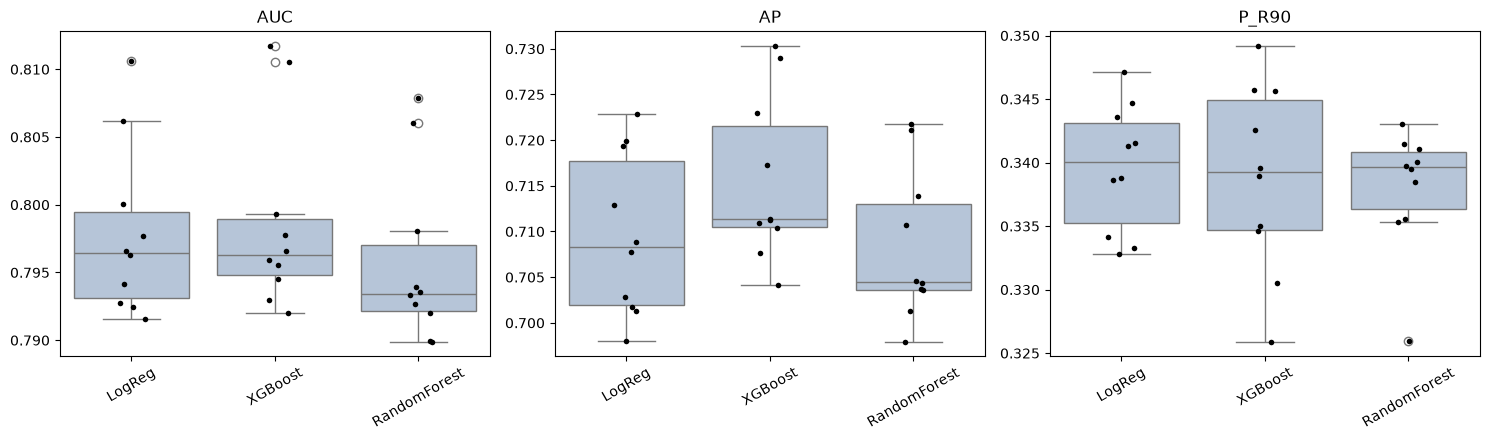

In [35]:
long = (pd.concat(SCORES_PLIS, names=["modele", "pli"]).reset_index()
          .melt(id_vars=["modele", "pli"], var_name="metrique", value_name="score"))

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
for a, m in zip(ax, ["AUC", "AP", "P_R90"]):
    d = long[long["metrique"] == m]
    sns.boxplot(data=d, x="modele", y="score", ax=a, color="lightsteelblue")
    sns.stripplot(data=d, x="modele", y="score", ax=a, color="black", size=4)     # un point par pli
    a.set_title(m)
    a.set_xlabel("")
    a.set_ylabel("")
    a.tick_params(axis="x", rotation=30)
plt.tight_layout()
plt.show()

### 6.2 Réglage des hyperparamètres
Pour les finalistes (`FINALISTES`), on utilise une **recherche aléatoire** (`RandomizedSearchCV`), plus économe qu'une grille, avec **AP** comme critère de réglage (`P_R90` est trop bruitée).
**Validation croisée imbriquée** : pour chaque pli externe, la recherche se fait sur le train du pli (3 sous-plis), puis le modèle réglé est évalué sur le pli de validation, qu'il n'a jamais vu. Les scores ne sont donc pas gonflés par le réglage.
On ne règle pas `class_weight` ni `scale_pos_weight` : nos métriques dépendent du classement des probabilités, et le déséquilibre se traite par le seuil (6.4).
Les hyperparamètres finaux sont la **médiane** des meilleurs réglages des 5 plis. ⚠️ Calcul long (≈ 10 × `N_ITER` × 3 entraînements par modèle) : résultat mis en cache.

In [36]:
N_ITER = 20
FINALISTES = ["LogReg", "XGBoost"]      # le vote (6.3) suppose ces deux modèles
RECALCULER_REGLAGE = False

ESPACES = {
    "LogReg":       {"C": loguniform(1e-3, 1e2)},
    "XGBoost":      {"n_estimators": randint(200, 800), "learning_rate": loguniform(0.02, 0.2),
                     "max_depth": randint(2, 7), "min_child_weight": randint(1, 30),
                     "subsample": uniform(0.6, 0.4), "colsample_bytree": uniform(0.5, 0.5)},
    "RandomForest": {"max_depth": randint(4, 16), "min_samples_leaf": randint(5, 100),
                     "max_features": uniform(0.3, 0.6)},
}


def cv_imbrique(nom):
    '''
    Pour chaque pli : recherche aléatoire sur le train du pli, puis score sur la validation du pli.
    Rend les scores, les prédictions hors-pli et les meilleurs paramètres de chaque pli.
    '''
    scores, preds, params = [], [], []
    for k in range(N_SPLITS):
        f = load_fold(chemin, k)
        recherche = RandomizedSearchCV(MODELES[nom](), ESPACES[nom], n_iter=N_ITER, cv=3,
                                       scoring="average_precision", random_state=SEED)
        recherche.fit(f["Xtr"][:, IDX[k]], f["ytr"])
        p = recherche.predict_proba(f["Xva"][:, IDX[k]])[:, 1]
        scores.append(scores_pli(f["yva"], p))
        preds.append(p)
        params.append(recherche.best_params_)
    return scores, preds, params


fichier = CACHE / f"reglage_{TAG}_{N_SPLITS}plis.joblib"
if fichier.exists() and not RECALCULER_REGLAGE:
    REGLAGE = joblib.load(fichier)
else:
    REGLAGE = {nom: cv_imbrique(nom) for nom in FINALISTES}
    joblib.dump(REGLAGE, fichier)

PARAMS_FINAUX = {}
for nom, (scores, _, params) in REGLAGE.items():
    df = pd.DataFrame(params)
    PARAMS_FINAUX[nom] = {c: int(round(df[c].median())) if pd.api.types.is_integer_dtype(df[c])
                          else float(df[c].median()) for c in df}
    print(f"{nom} (réglé) :", PARAMS_FINAUX[nom])
    display(pd.DataFrame(scores).agg(["mean", "std"]).round(4))

LogReg (réglé) : {'C': 0.028585493941961918}


,AUC,AP,P_R90
mean,0.7978,0.7095,0.3395
std,0.0062,0.0088,0.0051


XGBoost (réglé) : {'colsample_bytree': 0.5993578407670862, 'learning_rate': 0.020255926514662966, 'max_depth': 4, 'min_child_weight': 19, 'n_estimators': 792, 'subsample': 0.88453678109946}


,AUC,AP,P_R90
mean,0.7989,0.7156,0.3380
std,0.0071,0.0092,0.0052


### 6.3 Vote entre la régression logistique et XGBoost
On moyenne les probabilités : `p = w * p_xgb + (1 - w) * p_logreg`. Les extrémités `w = 0` et `w = 1` sont les modèles seuls : le vote n'est utile que s'il bat les deux.
Les prédictions viennent des plis de validation (jamais vues par les modèles). Avec un seul paramètre `w`, le biais de sélection reste faible.

In [37]:
y_val = [load_fold(chemin, k)["yva"] for k in range(N_SPLITS)]
P = {nom: REGLAGE[nom][1] for nom in ("LogReg", "XGBoost")}

lignes = []
for w in np.arange(0, 1.01, 0.1):                  # poids de XGBoost
    sc = pd.DataFrame([scores_pli(y_val[k], w * P["XGBoost"][k] + (1 - w) * P["LogReg"][k])
                       for k in range(N_SPLITS)])
    lignes.append({"w_xgb": round(w, 1), **sc.mean().to_dict()})

vote = pd.DataFrame(lignes).set_index("w_xgb")
W_XGB = vote["AP"].idxmax()
print(f"meilleur poids XGBoost (AP) : {W_XGB}")
display(vote.style.format("{:.4f}").highlight_max(axis=0))

meilleur poids XGBoost (AP) : 0.7


,AUC,AP,P_R90
w_xgb,,,
0.000000,0.7978,0.7095,0.3395
0.100000,0.7984,0.7115,0.3395
0.200000,0.7989,0.7130,0.3395
0.300000,0.7992,0.7142,0.3390
0.400000,0.7995,0.7150,0.3397
0.500000,0.7997,0.7156,0.3404
0.600000,0.7998,0.7160,0.3411
0.700000,0.7998,0.7162,0.3413
0.800000,0.7997,0.7162,0.3400


### 6.4 Seuil de décision
Le modèle sort une probabilité ; il faut un **seuil** pour décider « diabétique ». Objectif : détecter au moins 90 % des diabétiques (`RAPPEL_CIBLE`). On prend le plus grand seuil qui atteint ce rappel sur les prédictions hors-pli, et on regarde la précision obtenue (part de vrais diabétiques parmi les alertes).
On sauvegarde ensuite tout le nécessaire pour l'évaluation finale sur le jeu de test (à ne faire qu'une fois).

In [38]:
p_oof = np.concatenate([W_XGB * P["XGBoost"][k] + (1 - W_XGB) * P["LogReg"][k] for k in range(N_SPLITS)])
y_oof = np.concatenate(y_val)

prec, rec, seuils = precision_recall_curve(y_oof, p_oof)
SEUIL = seuils[rec[:-1] >= RAPPEL_CIBLE].max()
alertes = p_oof >= SEUIL
print(f"seuil = {SEUIL:.3f} | rappel = {y_oof[alertes].sum() / y_oof.sum():.3f} | précision = {y_oof[alertes].mean():.3f}")

joblib.dump({"colonnes": COLS_FINALES, "params": PARAMS_FINAUX, "w_xgb": W_XGB, "seuil": SEUIL},
            CACHE / f"modele_final_{TAG}_{N_SPLITS}plis.joblib")

seuil = 0.108 | rappel = 0.900 | précision = 0.340


['cache_selection\\modele_final_full_10plis.joblib']

## 7. Validation du modèle final
Dernière étape : on mesure la performance sur le **jeu de test** (20 %, `random_state=42`), mis de côté depuis le début. Il sert **une seule fois**, sans plus rien modifier ensuite (colonnes, hyperparamètres, poids du vote et seuil sont déjà figés par la section 6).
Pour mémoire, les estimations en validation croisée (section 6) étaient : AUC ≈ 0,800, AP ≈ 0,717, précision ≈ 0,342 pour 90 % de rappel.

### 7.1 Performances sur le jeu de test
Le prétraitement (`Clean`) et les deux modèles sont **réajustés sur tout le train**, puis appliqués au test. On compare :
- les modèles seuls et le vote, avec la baseline `Dummy` comme repère ;
- un **intervalle de confiance à 95 %** du vote par bootstrap (rééchantillonnage du test), pour savoir de combien les chiffres peuvent bouger ;
- le comportement au **seuil choisi en 6.4** : rappel, précision, F1 et matrice de confusion.

train : 78,384 lignes | test : 19,596 lignes | 27 colonnes


,AUC,AP,P_R90
Dummy,0.5000,0.2797,0.2797
LogReg,0.7954,0.7069,0.3380
XGBoost,0.7962,0.7131,0.3378
Vote,0.7973,0.7137,0.3375


Vote, IC 95 % :


,bas,haut
AUC,0.7902,0.8060
AP,0.7025,0.7260
P_R90,0.3292,0.3482


seuil = 0.108 | rappel = 0.897 | précision = 0.339 | F1 = 0.492 | alertes = 74.0% des patients


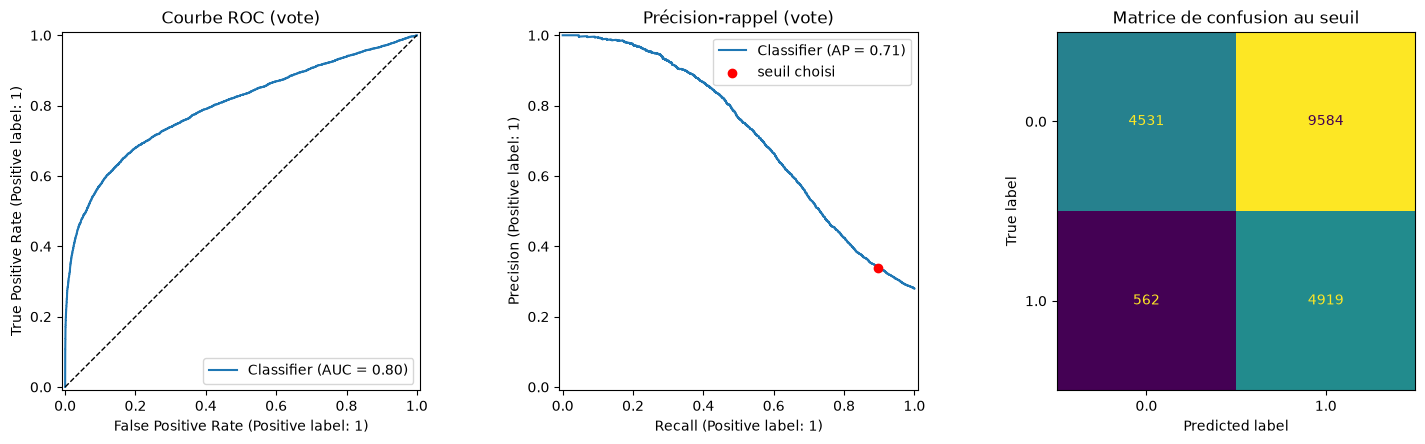

In [39]:
from sklearn.metrics import PrecisionRecallDisplay

FINAL = joblib.load(CACHE / f"modele_final_{TAG}_{N_SPLITS}plis.joblib")
COLS, PARAMS, W_XGB, SEUIL = FINAL["colonnes"], FINAL["params"], FINAL["w_xgb"], FINAL["seuil"]

# même découpage que donnees() : on récupère cette fois le jeu de test
X_all = diabete.drop("diabetes_status", axis=1)
y_all = diabete["diabetes_status"]
X_tr, X_te, y_tr, y_te = train_test_split(X_all, y_all, test_size=0.2, stratify=y_all, random_state=SEED)

prep = Clean(diabete, target="diabetes_status", crossval=True)
Xtr = prep.fit_transform(X_tr)[COLS]            # prétraitement ajusté sur le train complet uniquement
Xte = prep.transform(X_te)[COLS]
print(f"train : {len(Xtr):,} lignes | test : {len(Xte):,} lignes | {len(COLS)} colonnes")

modeles = {
    "Dummy":   DummyClassifier(strategy="prior"),
    "LogReg":  LogisticRegression(max_iter=2000, **PARAMS["LogReg"]),
    "XGBoost": make_xgb(**PARAMS["XGBoost"]),
}
P_TE = {nom: m.fit(Xtr, y_tr).predict_proba(Xte)[:, 1] for nom, m in modeles.items()}
P_TE["Vote"] = W_XGB * P_TE["XGBoost"] + (1 - W_XGB) * P_TE["LogReg"]

y_np = y_te.to_numpy()
display(pd.DataFrame({nom: scores_pli(y_np, p) for nom, p in P_TE.items()}).T.style.format("{:.4f}"))

# intervalle de confiance à 95 % du vote (bootstrap du jeu de test)
rng = np.random.default_rng(SEED)
tirages = (rng.integers(0, len(y_np), len(y_np)) for _ in range(300))
boot = pd.DataFrame([scores_pli(y_np[i], P_TE["Vote"][i]) for i in tirages])
print("Vote, IC 95 % :")
display(boot.quantile([0.025, 0.975]).T.rename(columns={0.025: "bas", 0.975: "haut"}).round(4))

# au seuil choisi en 6.4
pred = P_TE["Vote"] >= SEUIL
rappel, precision = y_np[pred].sum() / y_np.sum(), y_np[pred].mean()
print(f"seuil = {SEUIL:.3f} | rappel = {rappel:.3f} | précision = {precision:.3f} | F1 = {f1_score(y_np, pred):.3f} "
      f"| alertes = {pred.mean():.1%} des patients")

fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
RocCurveDisplay.from_predictions(y_np, P_TE["Vote"], ax=ax[0])
ax[0].plot([0, 1], [0, 1], "k--", lw=1)
PrecisionRecallDisplay.from_predictions(y_np, P_TE["Vote"], ax=ax[1])
ax[1].scatter(rappel, precision, color="red", zorder=3, label="seuil choisi")
ax[1].legend()
ConfusionMatrixDisplay.from_predictions(y_np, pred, ax=ax[2], colorbar=False)
ax[0].set_title("Courbe ROC (vote)")
ax[1].set_title("Précision-rappel (vote)")
ax[2].set_title("Matrice de confusion au seuil")
plt.tight_layout()
plt.show()

### 7.2 Hyperparamètres et variables importantes
Récapitulatif de ce qui définit le modèle final : hyperparamètres retenus (médiane des plis, section 6.2), poids du vote, seuil et colonnes.
Pour l'interprétation : le **gain** de XGBoost mesure l'apport d'une variable aux découpages de ses arbres ; les **coefficients** de la régression logistique sont comparables entre eux car les variables sont standardisées (signe positif = augmente le risque).

poids XGBoost dans le vote : 0.7 | seuil de décision : 0.108 | 27 colonnes


,LogReg,XGBoost
C,0.028585,-
colsample_bytree,-,0.599358
learning_rate,-,0.020256
max_depth,-,4.0
min_child_weight,-,19.0
n_estimators,-,792.0
subsample,-,0.884537


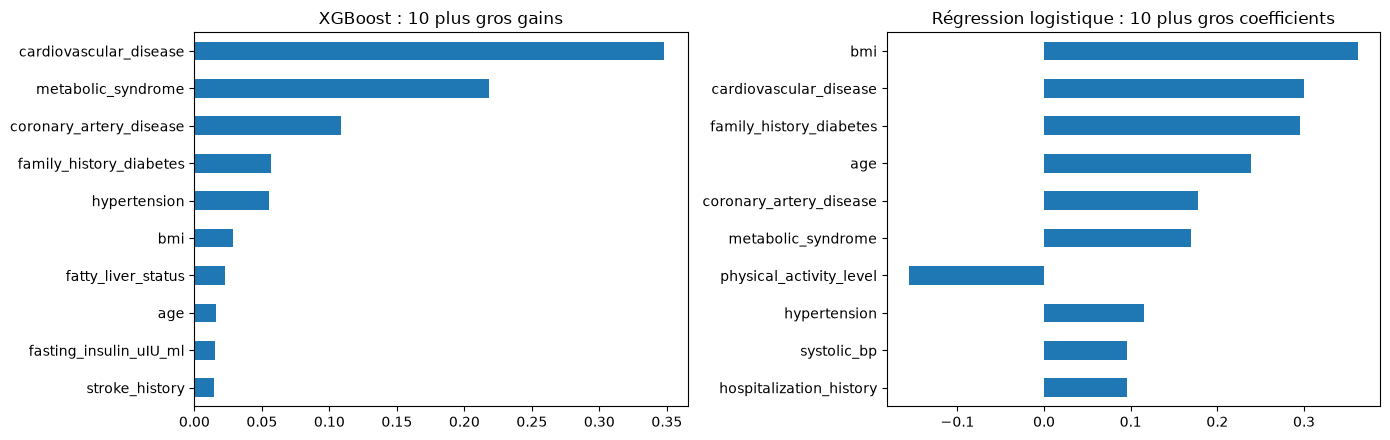

Colonnes retenues : ['ast_u_l', 'coronary_artery_disease', 'smoking_status', 'emergency_visit_history', 'cardiovascular_disease', 'hdl_mg_dl', 'fasting_insulin_uIU_ml', 'weight_kg', 'hypertension', 'daily_steps', 'fatty_liver_status', 'age', 'fiber_grams_per_day', 'years_smoked', 'metabolic_syndrome', 'cardiovascular_complication', 'systolic_bp', 'physical_activity_level', 'bmi', 'waist_circumference_cm', 'egfr_ml_min_1_73m2', 'hospitalization_history', 'diastolic_bp', 'stroke_history', 'triglycerides_mg_dl', 'family_history_diabetes', 'sleep_hours']


In [40]:
print(f"poids XGBoost dans le vote : {W_XGB} | seuil de décision : {SEUIL:.3f} | {len(COLS)} colonnes")
display(pd.DataFrame(PARAMS).fillna("-"))

gain = pd.Series(modeles["XGBoost"].feature_importances_, index=COLS).nlargest(10)
coef = pd.Series(modeles["LogReg"].coef_[0], index=COLS)
coef = coef.reindex(coef.abs().nlargest(10).index)

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
gain[::-1].plot.barh(ax=ax[0], title="XGBoost : 10 plus gros gains")
coef[::-1].plot.barh(ax=ax[1], title="Régression logistique : 10 plus gros coefficients")
plt.tight_layout()
plt.show()

print("Colonnes retenues :", COLS)

### 7.3 Bilan
- **Modèle final** : vote pondéré entre une régression logistique et un XGBoost réglés, sur 27 colonnes (sur 178 après prétraitement), seuil fixé pour détecter 90 % des diabétiques.
- **À comparer** : si les chiffres du test sont proches de ceux de la validation croisée (écart de l'ordre de l'écart-type, ≈ 0,005 d'AUC), le modèle généralise et la sélection de colonnes n'a pas surappris.
- **Plafond de performance** : logreg, XGBoost, forêt et vote donnent tous une AUC ≈ 0,80. Les données semblent limiter la performance bien plus que le choix du modèle, et le réglage n'a gagné que quelques millièmes.
- **Limite principale** : pour 90 % de rappel, la précision est d'environ 0,34 (le taux de diabétiques est de 28 %). Autrement dit, environ 2 alertes sur 3 sont de fausses alertes. Le modèle convient comme **outil de dépistage** (orienter vers un examen), pas comme diagnostic.
- **Pistes** : ajuster le compromis rappel/précision selon le coût d'une fausse alerte, ou chercher de nouvelles variables plutôt que de nouveaux modèles.